# IS453 Group Assignment — Components 4 to 7
## Logistic regression, tuning, scorecard, cutoff, interest rate, profit and walkthrough
**Segment:** First property purchase loans  |  **Input:** the screened characteristics and bins from Component 3 (`IS453_Component_3.ipynb`)  |  **Output:** a scaled scorecard, a cutoff and interest rates, and its performance on unseen applicants.

| Section | Brief component | Content | Course methods | Data |
|---|---|---|---|---|
| A | - | Training and test sets: separate and stratified | FA11.3 s5 | Train, split counts |
| B | 4 Logistic regression | Logistic regression on WOE inputs; class weights | FA9.3, FA11.1; Week 9 and 11 labs | Train |
| C | 5 Model tuning | Removing, substituting, adding and re-ranging characteristics; a separate scorecard for no-file applicants | FA11.4 s5-7, FA11.3 s17, FA7.2 s9; Week 9 lab DIY Q3 | Train |
| D | 4 and 7 | Final model and scaled scorecard | FA11.1, FA11.2; `sc.scorecard` (Week 11 lab) | Train |
| E | 6 Cutoff and profit | Revenue, expected defaults, expense and profit by cutoff | FA11.4 s8-12; Week 11 lab | Train |
| F | 6 Interest rate and profit | Portfolio rate, risk-based rates, profit by score band | FA7.1 s3-4, s8; FA7.2 s10 | Train |
| G | 4 Model performance | ROC and AUC, confusion matrix and PCC measures, expected against actual defaults, PSI | FA11.3, FA11.4 s13; Week 11 lab | **Test, opened once** |
| H | Risks | Approval and default rates by customer segment | FA7.1 s14, FA7.2 s11 | Test and train |
| I | 7 Walkthrough | Scoring example applicants | `sc.scorecard_ply` (Week 11 lab) | New examples |
| J | Risks and summary | Limitations, summary numbers, references | - | - |

**Reading the numbers.** `TARGET = 1` is Bad. `scorecardpy` computes WOE as ln(%Bad ÷ %Good), so a riskier bin has a **positive** WOE and sensible characteristics get **positive** coefficients. The slides' convention, ln(%Good ÷ %Bad), only flips both signs, so the points are the same (section D). A higher score means a lower chance of default.

## Why this scorecard puts inclusion ahead of specificity
Specificity measures how many future defaulters a scorecard turns away, and a strict cutoff raises it. We deliberately do not make it the main goal, because of what this product is for. All figures below come from training applicants and are produced in section E.

**1. The product exists for people early in their credit life.** A first property loan goes to people who have never owned a home: 61% of our applicants are under 40, and 20% of those aged 21-29 have no bureau file at all, against 12% of those aged 50-55. Raising the cutoff from 494 to 515 would lift specificity from 26% to 66%, but cut the good payers approved among 21-29 year olds from 85% to 49%, against 95% to 70% for those aged 50-55. That would largely turn people away for having a short history, not for repaying badly.

**2. Specificity counts only one side of the cost.** It ignores the good payers refused on the way. Moving from 494 to the most profitable cutoff, 505, avoids 189 defaulters per 10,000 applicants but turns away 1,091 good payers, almost 6 for each defaulter avoided. Of those turned away, 31% are aged 21-29 (23% of applicants) and 17% have no bureau file (14% of applicants), so the cost falls hardest on the core customers.

**3. A secured home loan can carry this risk better than an unsecured one.** The loan is capped at 75% of the property's value (collateral, FA7.1 s10; MAS, n.d.-a), so we assume a bank loses about 20% of the loan on default rather than most of it. MSR and TDSR limits screen affordability before the scorecard (MAS, n.d.-b), and risk-based rates recover the extra expected loss from lower-scoring loans (FA7.2 s10, section F).

**4. The outcome we model overstates mortgage default.** `TARGET` records payment difficulties on short consumer loans, an earlier and more frequent event than default on a home loan. So the defaults, and the cost of inclusion, are likely to be smaller than the figures here.

**5. Fairness is part of choosing a scorecard.** Lending bias is a concern the course raises directly (FA7.1 s14), fairness and regulatory concerns are among the reasons banks use scorecards (FA7.2 s11), and the final choice should weigh business objectives, market share and regulatory compliance as well as performance (FA11.4 s7). Singapore supports this segment strongly: first-timer families can receive up to S$120,000 in Enhanced CPF Housing Grant for a new flat (HDB, 2026b).

**How applicants are still evaluated fairly.**
- Everyone in a segment is scored on the same characteristics and points, and **everyone faces the same cutoff**. The two scorecards (with and without a bureau file, FA7.2 s9) use the same scaling and one table that turns a score into a PD.
- Gender, age, education, region and family characteristics are not inputs (section C, round 2). They are used only to measure outcomes.
- Risk still decides the order. On unseen applicants, those below the cutoff default at 21.2% against 7.7% of those approved (section G).

**What this costs, stated plainly.** Compared with the most profitable cutoff, specificity falls from 46% to 26%, and the bad rate among approved applicants rises from 6.4% to 7.6%, still below the 9.2% of approving everyone. Profit falls by S$2.59m per 10,000 applicants (6%), or about S$2,370 for each extra good payer served. Profit is still about S$10m above approving everyone. If loss given default were above about 33%, the recommended cutoff would lose money at a flat 2.00% rate, so management must confirm that assumption.

## 0. Settings
Every choice sits in one place. The business values are **assumptions for the team to confirm**, not facts from the data; section J lists their sources.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
import scorecardpy as sc

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 90)

C3_DIR = Path("component3_outputs")     # bins and data split from Component 3
OUT    = Path("component4_outputs")     # tables and charts for the slides
OUT.mkdir(exist_ok=True)

# ---- Scorecard scaling (Week 11 lab): 600 points at 1:19 odds of default (5% PD), 20 points to double the odds ----
POINTS0, ODDS0, PDO = 600, 1 / 19, 20

# ---- Model tuning (section C) ----
MIN_VARS, MAX_VARS = 8, 15   # scorecards usually have 8 to 15 characteristics (FA7.2 s3)
AUC_TOLERANCE  = 0.001  # a loss of training AUC smaller than this, measured from the start of a tuning round, is treated as no loss (team rule)
MUST_KEEP      = ["BUR_ANY_ADVERSE"]   # payment history: the number of delinquencies is a core scorecard variable (FA7.2 s6)
# Characteristics left out of the scorecard on purpose (section C, round 2)
FAIRNESS_EXCLUDE = {   # they describe who a person is rather than how they use credit, and can disadvantage groups (FA7.1 s14, FA7.2 s11)
    "NAME_EDUCATION_TYPE": "education level, a socio-economic proxy", "AGE_YEARS": "age, a protected characteristic",
    "REGION_RATING_CLIENT": "region rating, a geographic and socio-economic proxy", "REGION_RATING_CLIENT_W_CITY": "region rating, city-adjusted",
    "REGION_POPULATION_RELATIVE": "region population density, a geographic proxy", "NAME_HOUSING_TYPE": "current living arrangement",
    "NAME_FAMILY_STATUS": "family status", "CNT_CHILDREN": "number of children", "CNT_FAM_MEMBERS": "family size"}
LOCAL_FIT_EXCLUDE = {  # they cannot be collected or would not mean the same for a Singapore first-property applicant (FA9.1 s18)
    "REG_CITY_NOT_LIVE_CITY": "Singapore is a single city", "REG_CITY_NOT_WORK_CITY": "Singapore is a single city",
    "LIVE_CITY_NOT_WORK_CITY": "Singapore is a single city", "AMT_INCOME_TOTAL": "income is not in SGD, so its bins would not transfer"}

# ---- Business assumptions for one first-property loan (section J lists sources) ----
PROPERTY_PRICE    = 630_000    # about the median 4-room HDB resale price, SGD
LTV               = 0.75       # maximum loan-to-value on a first housing loan (MAS)
LOAN_AMOUNT       = PROPERTY_PRICE * LTV
HOLDING_YEARS     = 5          # how long the bank expects to hold the loan before it is refinanced or repaid
AVG_BALANCE_SHARE = 0.92       # assumption: share of the loan still owed, on average, over 5 years of a 25-year repayment schedule
REFERENCE_RATE    = 0.0200     # customer rate used while choosing the cutoff, in line with advertised packages
FUNDING_COST      = 0.0120     # about 3-month SORA: the bank's cost of funds
OPERATING_COST    = 0.0025     # servicing cost per year
TARGET_MARGIN     = 0.0030     # profit margin the bank wants on top of all costs
RATE_CEILING      = 0.0260     # a rate above the HDB concessionary loan rate would not be competitive
LGD               = 0.20       # share of the loan lost when a borrower defaults, after selling the property
APPLICANTS        = 10_000     # profit is quoted per 10,000 applicants, as in FA11.4 s10-12

# Revenue per loan: net interest margin on the money lent (FA7.1 s3), over the holding period (FA11.4 s10)
REVENUE_PER_LOAN = LOAN_AMOUNT * AVG_BALANCE_SHARE * (REFERENCE_RATE - FUNDING_COST - OPERATING_COST) * HOLDING_YEARS
LOSS_PER_DEFAULT = LOAN_AMOUNT * LGD   # average loss per loan default (FA11.4 s11)
CUTOFF_GRID      = range(420, 641)
REVIEW_BAND      = 5           # scores within 5 points of the cutoff go to manual review (FA7.1 s11)

# ---- No customer segment left behind: the team's business rule for this product (section E) ----
MIN_APPROVAL_RATIO = 0.80      # every customer group is approved at no less than 80% of the best-treated group's rate in its family
MIN_GROUP_TRAIN    = 500       # smaller groups are too small to judge (about 1% of the training set)
FIRST_BUYER_CROSSINGS = [("Age", "Gender"), ("Age", "Bureau file"), ("Age", "Education"), ("Age", "Family status"),
                         ("Age", "Children"), ("Bureau file", "Gender"), ("Bureau file", "Education")]

# ---- Helpers ----
ORIGINAL_NAMES = {"App_Data.csv": "IS453 Group Assignment - Application Data.csv",
                  "Bureau_Data.csv": "IS453 Group Assignment - Bureau Data.csv"}

def raw_file(name):
    # the raw file under our short name or the name it was supplied with, in any capitalisation
    for candidate in (name, ORIGINAL_NAMES[name]):
        found = next((p for p in Path(".").iterdir() if p.name.lower() == candidate.lower()), None)
        if found:
            return found
    raise FileNotFoundError(f"Put {name} or '{ORIGINAL_NAMES[name]}' in {Path.cwd()}")

def odds_good(score):
    # good:bad odds implied by a score (FA11.4 s9; Week 11 lab): 19 at 600, doubling every 20 points
    return 19 * 2 ** ((np.asarray(score, dtype=float) - POINTS0) / PDO)

def pd_from_score(score):
    # probability of default implied by a score: p = 1 / (1 + odds) (FA11.5 s7; Week 11 lab)
    return 1 / (1 + odds_good(score))

def auc(y_true, score):
    # AUC (FA11.3 s17); a higher score means safer, so the score is negated to rank Bads first
    return metrics.roc_auc_score(y_true, -np.asarray(score))

## A. Training and test sets: separate and stratified
A model is only worth trusting if it is judged on applicants it has never seen, and if both sets look like the same population (FA11.3 s4-5). Component 3 split the 72,292 applicants once, 70% for training and 30% for testing, with `sc.split_df` stratified on `TARGET`, and built every bin from training rows only.

This section checks the split with simple counts. It reads the list of who is in which set and the outcome counts; it does not read any test applicant's characteristics, and nothing here feeds the model. The test applicants' data is opened only in section G.

In [2]:
c3 = json.load(open(C3_DIR / "bins_and_breaks.json"))
retained, breaks = c3["retained"], c3["breaks_list"]
train = pd.read_csv(C3_DIR / "train.csv")
split_ids = pd.read_csv(C3_DIR / "split_ids.csv")
y = train["TARGET"].to_numpy()

# Fields used only to measure outcomes by customer segment; none of them is a scorecard input
audit_cols = ["SK_ID_CURR", "TARGET", "CODE_GENDER", "DAYS_BIRTH", "NAME_CONTRACT_TYPE", "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE",
              "NAME_HOUSING_TYPE", "REGION_RATING_CLIENT", "NAME_FAMILY_STATUS", "CNT_CHILDREN"]
audit_raw = pd.read_csv(raw_file("App_Data.csv"), usecols=audit_cols).set_index("SK_ID_CURR")
bureau_ids = set(pd.read_csv(raw_file("Bureau_Data.csv"), usecols=["SK_ID_CURR"])["SK_ID_CURR"])

train_ids = split_ids.loc[split_ids["Set"] == "train", "SK_ID_CURR"]
test_ids = split_ids.loc[split_ids["Set"] == "test", "SK_ID_CURR"]
assert not set(train_ids) & set(test_ids) and set(train["SK_ID_CURR"]) == set(train_ids)
counts = pd.DataFrame({"Applicants": [len(train_ids), len(test_ids)],
                       "Bads": [audit_raw["TARGET"].reindex(train_ids).sum(), audit_raw["TARGET"].reindex(test_ids).sum()]}, index=["Train", "Test"])
counts["Bad_rate"] = counts["Bads"] / counts["Applicants"]
print(f"No applicant is in both sets: train {len(train_ids):,} + test {len(test_ids):,} = {len(train_ids) + len(test_ids):,}")
display(counts.round(5))


def segment_groups(ids, crossings=True):
    # every customer segment we audit, as one label per applicant
    raw = audit_raw.reindex(pd.Series(ids).to_numpy())
    age = -raw["DAYS_BIRTH"].to_numpy() / 365.25
    groups = {"Age": np.array(pd.cut(age, [20, 30, 40, 50, 56], right=False, labels=["21-29", "30-39", "40-49", "50-55"]).astype(str)),
              "Gender": raw["CODE_GENDER"].astype(str).to_numpy(),
              "Family status": raw["NAME_FAMILY_STATUS"].astype(str).to_numpy(),
              "Children": np.minimum(raw["CNT_CHILDREN"].to_numpy(), 3).astype(int).astype(str),
              "Bureau file": np.where(pd.Series(ids).isin(bureau_ids).to_numpy(), "Has a file", "No file"),
              "Product": raw["NAME_CONTRACT_TYPE"].astype(str).to_numpy(),
              "Education": raw["NAME_EDUCATION_TYPE"].astype(str).to_numpy(),
              "Income type": raw["NAME_INCOME_TYPE"].astype(str).to_numpy(),
              "Housing": raw["NAME_HOUSING_TYPE"].astype(str).to_numpy(),
              "Region rating": raw["REGION_RATING_CLIENT"].astype(str).to_numpy()}
    if crossings:
        for a, b in FIRST_BUYER_CROSSINGS:
            groups[f"{a} x {b}"] = np.char.add(np.char.add(groups[a].astype(str), " x "), groups[b].astype(str))
    return groups


# Stratification on TARGET should also leave the customer mix balanced: compare each group's share of the two sets
train_groups, test_groups = segment_groups(train_ids, crossings=False), segment_groups(test_ids, crossings=False)
mix = pd.DataFrame({f: {"Largest_gap_in_share_pct_points": (pd.Series(train_groups[f]).value_counts(normalize=True)
                                                          - pd.Series(test_groups[f]).value_counts(normalize=True)).abs().max() * 100}
                    for f in train_groups}).T
display(mix.round(2))

No applicant is in both sets: train 50,604 + test 21,688 = 72,292


,Applicants,Bads,Bad_rate
Train,50604,4656,0.09201
Test,21688,1996,0.09203


,Largest_gap_in_share_pct_points
Age,0.38
Gender,0.73
Family status,0.21
Children,0.45
Bureau file,0.14
Product,0.08
Education,0.10
Income type,1.20
Housing,0.32
Region rating,0.36


**How to read it.** The sets share no applicants, and stratification gives them the same bad rate (9.20% in both). The customer mix also matches: no group's share differs by more than 1.2 percentage points between the two sets (income type), and most by well under 1. So test results can be read as a fair sample of the same population.

# Component 4: Logistic regression
## B. Logistic regression on WOE inputs
**Why WOE inputs.** Logistic regression cannot use raw categories or missing values directly, and its coefficients are only comparable when inputs share a scale. Replacing each value with the WOE of its bin solves all three: categories, missing values and numbers all become WOE, a common scale (FA10.4 s3-6, FA11.1 s5). We rebuild Component 3's bins from its saved edges with `sc.woebin` and encode with `sc.woebin_ply`, as in the Week 11 lab, and fit `LogisticRegression(class_weight='balanced')`, the class weighting of the Week 9 lab.

**How models are compared.** As in the Week 9 lab's DIY Q3, each version of the model is fitted on the training data and compared with the others on the training data. FA11.3 s17 says AUC "can be used to compare ROC curves of different models to select best one", so AUC is the measure. The test set stays closed until section G, so it plays no part in any choice.

In [3]:
bins_train = sc.woebin(train[retained + ["TARGET"]], y="TARGET", breaks_list=breaks, check_cate_num=False, no_cores=1)   # Component 3's bins
train_woe = sc.woebin_ply(train[retained + ["TARGET"]], bins_train)                                                 # Week 11 lab
assert not train_woe.isna().any().any()


def X_of(variables, frame=None):
    return (train_woe if frame is None else frame)[[v + "_woe" for v in variables]]


def evaluate(variables, class_weight="balanced", frame=None):
    # fit on the training data and judge it there, as in the Week 9 lab (DIY Q3)
    X = X_of(variables, frame)
    model = LogisticRegression(class_weight=class_weight).fit(X, y)
    p = model.predict_proba(X)[:, 1]
    return {"Variables": len(variables), "AUC_train": metrics.roc_auc_score(y, p), "Mean_predicted_PD": p.mean(),
            "Negative_coefficients": [v for v, c in zip(variables, model.coef_[0]) if c < 0]}


model0 = LogisticRegression(class_weight="balanced").fit(X_of(retained), y)
coef0 = pd.DataFrame({"Coef": model0.coef_[0], "IV": [bins_train[v]["total_iv"].iloc[0] for v in retained]}, index=retained).sort_values("IV", ascending=False)
display(coef0.round(4))
base = evaluate(retained)
print(f"All {len(retained)} retained characteristics: training AUC {base['AUC_train']:.4f}")
print("Characteristics with a negative coefficient (wrong sign):", base["Negative_coefficients"] or "none")

[INFO] creating woe binning ...
[INFO] converting into woe values ...


,Coef,IV
EXT_SOURCE_1,0.6770,0.1621
BUR_DEBT_RATIO,0.4482,0.1218
BUR_MEAN_DAYS_CREDIT,0.2552,0.1041
BUR_CARD_UTIL,0.6372,0.0941
BUR_ACTIVE_SHARE,0.3571,0.0754
NAME_EDUCATION_TYPE,0.5598,0.0746
BUR_NEWEST_DAYS,0.3249,0.0743
OCCUPATION_TYPE,0.4054,0.0679
REGION_RATING_CLIENT_W_CITY,0.6749,0.0670
BUR_CNT_LAST_24M,0.0821,0.0560


All 25 retained characteristics: training AUC 0.7082
Characteristics with a negative coefficient (wrong sign): ['BUR_NUM_ACTIVE', 'BUR_CNT_CLOSED', 'AMT_INCOME_TOTAL']


**How to read it.** With all 25 characteristics, the training AUC is 0.708. Three coefficients have the wrong sign: the number of active credits, the number of closed credits and income. They overlap with other bureau characteristics, so once those are in the model their own effect flips. Round 1 deals with this.

### Class weights
With only about 9% Bads, the data is imbalanced (FA9.3 s20): a model fitted as it is learns mostly from Goods. The Week 9 lab fits `LogisticRegression(class_weight='balanced')`, which gives the Bads as much weight in the fit as the Goods, and this is the model we use throughout, for tuning and for the final scorecards. The lab also warns that it makes predicted probabilities higher than real default rates, so they should be read "as relative scores, not true probabilities of default". The comparison below, against the plain `LogisticRegression()` of the Week 11 lab, shows how large that effect is.

In [4]:
weights = pd.DataFrame({"Plain (Week 11 lab)": evaluate(retained, class_weight=None), "Balanced (Week 9 lab)": evaluate(retained, class_weight="balanced")}).T
weights["Actual_bad_rate"] = y.mean()
display(weights[["AUC_train", "Mean_predicted_PD", "Actual_bad_rate"]].astype(float).round(4))

,AUC_train,Mean_predicted_PD,Actual_bad_rate
Plain (Week 11 lab),0.7080,0.0920,0.092
Balanced (Week 9 lab),0.7082,0.4463,0.092


**How to read it.** The two versions rank applicants equally well (training AUC 0.708 for both), so the class weights do not change who is riskier than whom. But the balanced model predicts an average PD of 44.6% against a real bad rate of 9.2%. As the Week 9 lab says, its probabilities are relative scores. This matters in two places later:
- **Scores.** The scorecard's points still come from the balanced model, so the score ranks applicants correctly. But the 1:19 odds at 600 points no longer describe real odds: the scale would imply a bad rate of about 46%.
- **PDs for profit and pricing.** Every business number needs real default rates. So in section D, a score's PD is read from the training applicants with similar scores: the actual bad rate of their score group (section D shows the table). This uses only counts from the training data, in the same way as the Week 11 lab's comparison of expected and actual defaults.

Approvals are set by the score cutoff in section E, so nothing depends on the 0.5 threshold.

# Component 5: Model tuning
FA11.4 s5 lists the tuning moves: adding or removing characteristics, substituting characteristics, changing attribute ranges, and changing the number of attributes. FA11.4 s7 adds that the final choice should weigh overall performance, business objectives and regulatory compliance, not AUC alone. FA11.4 s6 adds that tuning may target a specific metric, such as misclassified Bads; we tune on AUC, which ranks all applicants, and deal with misclassified Bads when choosing the cutoff in section E. Each round below records the training AUC. A loss of AUC smaller than 0.001, measured from the start of the round, is treated as no loss (a team rule), so that several small losses cannot add up unnoticed.

## C. Tuning round 1: wrong signs
A characteristic whose coefficient has the wrong sign gives safer groups fewer points, which a scorecard cannot explain. With `scorecardpy`'s WOE convention every coefficient should be positive. Any wrong-sign characteristic is removed, one at a time, refitting after each.

In [5]:
current, tuning_log = list(retained), [{"Step": "Start: all retained characteristics", **evaluate(retained)}]
while True:
    model = LogisticRegression(class_weight="balanced").fit(X_of(current), y)
    wrong = {v: c for v, c in zip(current, model.coef_[0]) if c < 0}
    if not wrong:
        break
    v = min(wrong, key=wrong.get)
    current.remove(v)
    tuning_log.append({"Step": f"Round 1: remove {v} (wrong sign)", **evaluate(current)})
print("Removed for a wrong sign:", [r["Step"].split("remove ")[1].split(" ")[0] for r in tuning_log[1:]] or "none")

Removed for a wrong sign: ['BUR_CNT_CLOSED', 'AMT_INCOME_TOTAL']


## C2. Tuning round 2: characteristics left out on purpose
These characteristics are removed whatever their predictive power, for the reasons set in section 0:
- **Fairness.** Education, age, region, housing and family characteristics describe who a person is, not how they use credit. A scorecard that uses them can disadvantage groups of applicants, which is a lending-bias concern (FA7.1 s14) and against the fairness that is a reason for using scorecards at all (FA7.2 s11).
- **Local fit.** City flags cannot be collected for a Singapore applicant, and income is not in SGD, so their bins would not transfer (FA9.1 s18).

In [6]:
before_round2 = list(current)
excluded = [v for v in current if v in FAIRNESS_EXCLUDE or v in LOCAL_FIT_EXCLUDE]
current = [v for v in current if v not in excluded]
tuning_log.append({"Step": "Round 2: leave out fairness and local-fit exclusions", **evaluate(current)})
print("Left out:", {v: FAIRNESS_EXCLUDE.get(v, LOCAL_FIT_EXCLUDE.get(v)) for v in excluded})
print(f"Training AUC {evaluate(before_round2)['AUC_train']:.4f} -> {evaluate(current)['AUC_train']:.4f}")

Left out: {'NAME_EDUCATION_TYPE': 'education level, a socio-economic proxy', 'REGION_RATING_CLIENT_W_CITY': 'region rating, city-adjusted', 'AGE_YEARS': 'age, a protected characteristic', 'REGION_POPULATION_RELATIVE': 'region population density, a geographic proxy', 'NAME_HOUSING_TYPE': 'current living arrangement', 'REG_CITY_NOT_WORK_CITY': 'Singapore is a single city', 'REG_CITY_NOT_LIVE_CITY': 'Singapore is a single city'}
Training AUC 0.7072 -> 0.6937


**How to read it.** Leaving these seven characteristics out lowers the training AUC by 0.0135, from 0.707 to 0.694. That is the price of a scorecard that ranks applicants on how they use credit rather than on who they are, and that can be used for Singapore applicants. We accept it.

## C3. Tuning round 3: removing characteristics
A smaller scorecard is easier to explain and less likely to fit noise (FA9.1 s13-14, FA7.2 s3). Following the Week 9 lab's DIY Q3, at each step we remove the characteristic whose removal changes the AUC the least, and stop when the next removal would leave the AUC 0.001 or more below where this round started. Payment history (`BUR_ANY_ADVERSE`) is always kept.

In [7]:
round_start = evaluate(current)["AUC_train"]
while len(current) > MIN_VARS:
    now = evaluate(current)["AUC_train"]
    trials = {v: evaluate([x for x in current if x != v])["AUC_train"] for v in current if v not in MUST_KEEP}
    v = max(trials, key=trials.get)
    if round_start - trials[v] >= AUC_TOLERANCE and len(current) <= MAX_VARS:
        break
    current.remove(v)
    tuning_log.append({"Step": f"Round 3: remove {v} (AUC change {trials[v] - now:+.4f})", **evaluate(current)})
print(f"After round 3: {len(current)} characteristics")
display(pd.DataFrame(tuning_log).drop(columns="Negative_coefficients").set_index("Step").round(4))

After round 3: 13 characteristics


,Variables,AUC_train,Mean_predicted_PD
Step,,,
Start: all retained characteristics,25,0.7082,0.4463
Round 1: remove BUR_CNT_CLOSED (wrong sign),24,0.7073,0.4468
Round 1: remove AMT_INCOME_TOTAL (wrong sign),23,0.7072,0.4469
Round 2: leave out fairness and local-fit exclusions,16,0.6937,0.4531
Round 3: remove BUR_ACTIVE_SHARE (AUC change -0.0000),15,0.6937,0.4531
Round 3: remove BUR_NUM_ACTIVE (AUC change -0.0000),14,0.6937,0.4531
Round 3: remove BUR_CNT_LAST_24M (AUC change -0.0002),13,0.6935,0.4532


**How to read it.** Round 1 removed the number of closed credits and income; the number of active credits turned positive once those left. Round 3 then removed three bureau characteristics: the share of credits still active, the number of active credits and the number of credits opened in the last 24 months. Each changed the AUC by 0.0002 or less, because they repeat what the debt ratio and the newest credit already say. The next removal would have left the AUC 0.001 or more below the start of the round, so the round stopped at **13 characteristics**, inside the 8-15 range. The average credit age stays in (with the plain model it was removed at a cost of 0.0008).

## C4. Tuning round 4: substituting and adding characteristics
Two characteristics can carry similar information, and FA11.4 s5 suggests testing one in place of the other. Each remaining characteristic is swapped for the removed characteristic it is most correlated with, and the swap is kept only if it raises the AUC by at least 0.001. FA11.4 s5 also lists adding characteristics, so each removed characteristic is then tried back in, one at a time, under the same test.

In [8]:
removed = [v for v in retained if v not in current and v not in excluded]
corr = train_woe[[v + "_woe" for v in retained]].corr()
swaps = []
for v in [x for x in current if x not in MUST_KEEP]:
    if removed:
        partners = corr.loc[v + "_woe", [w + "_woe" for w in removed]].abs().sort_values(ascending=False)
        if partners.iloc[0] >= 0.3:
            w = partners.index[0][:-4]
            swaps.append({"Swap": f"{v} -> {w}", "Correlation": corr.loc[v + "_woe", w + "_woe"], **evaluate([w if x == v else x for x in current])})
reference = evaluate(current)
if swaps:
    swap_table = pd.DataFrame(swaps).drop(columns="Negative_coefficients")
    swap_table["AUC_change"] = swap_table["AUC_train"] - reference["AUC_train"]
    display(swap_table.set_index("Swap").round(4))
    best = swap_table.loc[swap_table["AUC_change"].idxmax()]
    if best["AUC_change"] >= AUC_TOLERANCE:
        v, w = best["Swap"].split(" -> ")
        current = [w if x == v else x for x in current]
        tuning_log.append({"Step": f"Round 4: substitute {w} for {v}", **evaluate(current)})
        print(f"Substituted {w} for {v}")
    else:
        print(f"No substitution raises the AUC by 0.001 or more (best: {best['Swap']}, {best['AUC_change']:+.4f}); the model is unchanged")
else:
    print("No removed characteristic is correlated 0.3 or more with one that stayed, so there is nothing to substitute")

# FA11.4 s5 also lists adding characteristics: each removed characteristic is tried back in, one at a time
reference = evaluate(current)
additions = pd.DataFrame([{"Add": w, **evaluate(current + [w])} for w in removed if w not in current]).set_index("Add")
additions["AUC_change"] = additions["AUC_train"] - reference["AUC_train"]
display(additions[["AUC_train", "AUC_change", "Negative_coefficients"]].round(4))
usable = additions[(additions["AUC_change"] >= AUC_TOLERANCE) & (additions["Negative_coefficients"].str.len() == 0)]
if len(usable):
    w = usable["AUC_change"].idxmax()
    current.append(w)
    tuning_log.append({"Step": f"Round 4: add {w}", **evaluate(current)})
    print(f"Added {w}")
else:
    print("No addition raises the AUC by 0.001 or more with sensible coefficients; the model is unchanged")


,Correlation,Variables,AUC_train,Mean_predicted_PD,AUC_change
Swap,,,,,
BUR_DEBT_RATIO -> BUR_ACTIVE_SHARE,0.5577,13,0.6912,0.4542,-0.0023
BUR_MEAN_DAYS_CREDIT -> BUR_CNT_CLOSED,0.5708,13,0.6927,0.4534,-0.0008
BUR_NEWEST_DAYS -> BUR_CNT_LAST_24M,0.6539,13,0.6929,0.4534,-0.0006


No substitution raises the AUC by 0.001 or more (best: BUR_NEWEST_DAYS -> BUR_CNT_LAST_24M, -0.0006); the model is unchanged


,AUC_train,AUC_change,Negative_coefficients
Add,,,
BUR_ACTIVE_SHARE,0.6935,0.0000,[]
BUR_CNT_LAST_24M,0.6937,0.0002,[]
BUR_NUM_ACTIVE,0.6936,0.0001,[]
BUR_CNT_CLOSED,0.6941,0.0006,[BUR_CNT_CLOSED]
AMT_INCOME_TOTAL,0.6936,0.0001,[]


No addition raises the AUC by 0.001 or more with sensible coefficients; the model is unchanged


## C5. Tuning round 5: changing attribute ranges for job tenure
Changing attribute ranges, and increasing or decreasing the number of attributes, are further tuning moves of FA11.4 s5. Component 3 set job tenure (`YEARS_EMPLOYED`) to a single split at 3 years. Here we compare it with the automatic bins `sc.woebin` would choose with its default settings. The question is whether the automatic bins, which run up to long tenures, predict better, and what they do to young applicants, who cannot have long tenure yet.

In [9]:
if "YEARS_EMPLOYED" in current:
    auto = sc.woebin(train[["YEARS_EMPLOYED", "TARGET"]], y="TARGET", check_cate_num=False, no_cores=1)     # Week 11 lab defaults
    tenure_woe = train_woe.copy()
    tenure_woe["YEARS_EMPLOYED_AUTO_woe"] = sc.woebin_ply(train[["YEARS_EMPLOYED"]], auto)["YEARS_EMPLOYED_woe"].to_numpy()
    with_auto = [("YEARS_EMPLOYED_AUTO" if v == "YEARS_EMPLOYED" else v) for v in current]
    tenure = pd.DataFrame({"One split at 3 years (chosen)": evaluate(current), "Automatic bins": evaluate(with_auto, frame=tenure_woe)}).T.drop(columns="Negative_coefficients")
    display(tenure.astype(float).round(4))
    print("Automatic tenure bins:")
    display(auto["YEARS_EMPLOYED"][["bin", "count_distr", "badprob", "woe"]].round(4))
    young = segment_groups(train["SK_ID_CURR"], crossings=False)["Age"] == "21-29"
    first_bin = auto["YEARS_EMPLOYED"].loc[~auto["YEARS_EMPLOYED"]["is_special_values"], "bin"].iloc[0]
    upper = float(first_bin.split(",")[1].rstrip(")"))
    in_first = train["YEARS_EMPLOYED"].to_numpy() < upper
    print(f"Share of 21-29 year olds in the lowest automatic tenure bin ({first_bin}): {in_first[young].mean():.0%} | of everyone else: {in_first[~young].mean():.0%}")

[INFO] creating woe binning ...
[INFO] converting into woe values ...


,Variables,AUC_train,Mean_predicted_PD
One split at 3 years (chosen),13.0,0.6935,0.4532
Automatic bins,13.0,0.6953,0.4522


Automatic tenure bins:


,bin,count_distr,badprob,woe
0,"[-inf,4.0)",0.4800,0.1125,0.2240
1,"[4.0,5.0)",0.0895,0.0987,0.0771
2,"[5.0,11.0)",0.2848,0.0744,-0.2319
3,"[11.0,inf)",0.1456,0.0548,-0.5580


Share of 21-29 year olds in the lowest automatic tenure bin ([-inf,4.0)): 69% | of everyone else: 41%


**How to read it.** Round 4 found no better substitute: swapping in the count of recent credits lowers the AUC by 0.0006, the number of closed credits by 0.0008, and the share of active credits by 0.0023. Adding a removed characteristic back does not help either: the number of closed credits adds the most (0.0006) but takes a wrong sign, and the others add 0.0002 or less.

On job tenure, the automatic bins have four attributes instead of two, starting with under 4 years in the job. They raise the training AUC by 0.0018, a small gain, but they make the scorecard partly an age scale: 69% of 21-29 year olds fall in the lowest bin, against 41% of everyone else. **We keep the single split at 3 years.** This is a business choice: FA11.4 s7 asks that the final scorecard weigh business objectives and regulatory compliance alongside performance, and lending bias is a concern the course raises directly (FA7.1 s14). The cost is 0.002 of AUC.

## C6. Tuning round 6: a separate scorecard for applicants with no bureau file
About one applicant in seven has no bureau file at all. In one scorecard they fall into the Missing bin of every bureau characteristic, so the single fact "no file" is scored several times over. FA7.2 s9 describes the course's answer: **scorecard segmentation**, a separate scorecard for customers "where the characteristics in the standard scorecard have not been established", such as new customers. Here that means two scorecards:
- applicants **with** a bureau file are scored on all the chosen characteristics, with WOE values and coefficients fitted on applicants with a file;
- applicants **without** a file are scored only on the characteristics they actually have (the non-bureau ones), fitted on applicants without a file.

Both use the same scaling (600 points at 1:19 odds, 20 points to double), and one table of score groups turns a score into a PD for both (section D), so **one cutoff applies to everyone**. We compare this with one scorecard: the AUC, and whether each reads the risk of no-file applicants correctly, using the Week 11 lab's comparison of expected and actual defaults. Because the balanced model's probabilities are relative, the expected bad rate here is the actual bad rate of the 20 equal groups of training applicants by predicted probability (`pd.qcut`, as in the Lab 10 fine classing).

**Bins inside each segment.** WOE is recomputed on each segment's own applicants, on fewer rows, so bins that were fine for all applicants can break the coarse classing rules of FA10.3 s11 inside a segment. As in the Week 10 lab's Ex Q3, we look at the bins and merge neighbours by hand, setting the new edges with `breaks_list`:
- **No file, `EXT_SOURCE_1`:** the 0.4-0.54 and 0.54-0.64 bins have the same WOE (-0.558 and -0.560), so they gave the same points. Edge 0.54 is removed.
- **No file, `OWN_CAR_AGE`:** the WOE zig-zags: 8-12 years looks riskier than 12-17 and 17+. Edges 12 and 17 are removed, leaving under 8 years and 8 years or more.
- **No file, `ORGANIZATION_TYPE`:** the safest employer group is only 4.3% of the segment, below the 5% minimum, so it joins the group with the nearest WOE.
- **With a file, `BUR_DEBT_RATIO`:** the Missing bin is only 3.4% of this segment, so it joins the 25%-50% bin, which has the nearest WOE (the Week 10 lab's Ex Q3 asks the same question of Missing).


In [10]:
FINAL_VARS = list(current)
no_file = ~train["SK_ID_CURR"].isin(bureau_ids).to_numpy()

# Inside a segment the WOE is recomputed on fewer applicants, so bins can break the rules of FA10.3 s11; edges set by hand (Week 10 lab Ex Q3, Week 11 lab breaks_list)
org = breaks["ORGANIZATION_TYPE"]
SEGMENT_BREAKS = {
    "Has a bureau file": {**breaks, "BUR_DEBT_RATIO": [0.25, "0.5%,%missing", 0.75]},                     # Missing is 3.4% of this segment: merged with the bin of nearest WOE
    "No bureau file": {**breaks, "EXT_SOURCE_1": [0.2, 0.4, 0.64],                                        # 0.4-0.54 and 0.54-0.64 have the same WOE: edge 0.54 removed
                       "OWN_CAR_AGE": [8.0],                                                              # 8-12 years is riskier than 12-17 and 17+: edges 12 and 17 removed
                       "ORGANIZATION_TYPE": [org[0] + "%,%" + org[1]] + org[2:]}}                         # the first group is 4.3% of this segment: merged with the group of nearest WOE
for name, rows, changed in [("Has a bureau file", ~no_file, ["BUR_DEBT_RATIO"]), ("No bureau file", no_file, ["EXT_SOURCE_1", "OWN_CAR_AGE", "ORGANIZATION_TYPE"])]:
    automatic = sc.woebin(train[rows][changed + ["TARGET"]], y="TARGET", breaks_list={v: breaks[v] for v in changed}, check_cate_num=False, no_cores=1)
    by_hand = sc.woebin(train[rows][changed + ["TARGET"]], y="TARGET", breaks_list={v: SEGMENT_BREAKS[name][v] for v in changed}, check_cate_num=False, no_cores=1)
    for v in changed:
        print(f"*** {name}, {v}: all-applicant edges | IV {automatic[v]['total_iv'].iloc[0]:.4f} ***")
        display(automatic[v].assign(bin=automatic[v]["bin"].str.slice(0, 40))[["bin", "count", "count_distr", "bad", "badprob", "woe"]].round(4))
        print(f"*** {name}, {v}: after merging by hand | IV {by_hand[v]['total_iv'].iloc[0]:.4f} ***")
        display(by_hand[v].assign(bin=by_hand[v]["bin"].str.slice(0, 40))[["bin", "count", "count_distr", "bad", "badprob", "woe"]].round(4))


def probabilities(segmented, variables=FINAL_VARS):
    # training PDs from one scorecard, or from one scorecard per bureau-file segment, each fitted on its own applicants
    parts = ([(~no_file, variables, SEGMENT_BREAKS["Has a bureau file"]), (no_file, [v for v in variables if not v.startswith("BUR_")], SEGMENT_BREAKS["No bureau file"])]
             if segmented else [(np.ones(len(train), bool), variables, breaks)])
    p = np.full(len(train), np.nan)
    for rows, vs, edges in parts:
        b = sc.woebin(train[rows][vs + ["TARGET"]], y="TARGET", breaks_list={v: edges[v] for v in vs}, check_cate_num=False, no_cores=1)
        X = sc.woebin_ply(train[rows][vs], b)[[v + "_woe" for v in vs]]
        p[rows] = LogisticRegression(class_weight="balanced").fit(X, y[rows]).predict_proba(X)[:, 1]
    return p


def compare(p):
    # balanced probabilities are relative (Week 9 lab note), so each applicant's expected PD is the actual bad rate of
    # the 20 equal groups of training applicants by predicted probability (pd.qcut, Lab 10), as for the scores in section D
    p = pd.Series(np.asarray(y)).groupby(pd.qcut(p, 20, labels=False, duplicates="drop")).transform("mean").to_numpy()
    return {"AUC_train": metrics.roc_auc_score(y, p), "No_file_expected_bad_rate": p[no_file].mean(), "No_file_actual_bad_rate": y[no_file].mean(),
            "With_file_expected_bad_rate": p[~no_file].mean(), "With_file_actual_bad_rate": y[~no_file].mean()}


segmentation = pd.DataFrame({"One scorecard": compare(probabilities(False)), "Separate no-file scorecard": compare(probabilities(True))}).T
display(segmentation.round(4))
gap = (segmentation["No_file_expected_bad_rate"] - segmentation["No_file_actual_bad_rate"]).abs()
SEGMENTED = bool(segmentation.loc["Separate no-file scorecard", "AUC_train"] >= segmentation.loc["One scorecard", "AUC_train"] - AUC_TOLERANCE
                 and gap["Separate no-file scorecard"] < gap["One scorecard"])
print("Decision:", "two scorecards, split by bureau file" if SEGMENTED else "one scorecard")

[INFO] creating woe binning ...
[INFO] creating woe binning ...
*** Has a bureau file, BUR_DEBT_RATIO: all-applicant edges | IV 0.1371 ***


,bin,count,count_distr,bad,badprob,woe
0,missing,1472,0.0338,117,0.0795,-0.1185
1,"[-inf,0.25)",19629,0.4511,1233,0.0628,-0.3718
2,"[0.25,0.5)",9650,0.2218,830,0.0860,-0.0325
3,"[0.5,0.75)",7769,0.1786,875,0.1126,0.2667
4,"[0.75,inf)",4991,0.1147,800,0.1603,0.6748


*** Has a bureau file, BUR_DEBT_RATIO: after merging by hand | IV 0.1369 ***


,bin,count,count_distr,bad,badprob,woe
0,"[-inf,0.25)",19629,0.4511,1233,0.0628,-0.3718
1,"[0.25,0.5)%,%missing",11122,0.2556,947,0.0851,-0.0435
2,"[0.5,0.75)",7769,0.1786,875,0.1126,0.2667
3,"[0.75,inf)",4991,0.1147,800,0.1603,0.6748


[INFO] creating woe binning ...
[INFO] creating woe binning ...
*** No bureau file, EXT_SOURCE_1: all-applicant edges | IV 0.1705 ***


,bin,count,count_distr,bad,badprob,woe
0,missing,3707,0.5226,470,0.1268,0.1315
1,"[-inf,0.2)",526,0.0742,106,0.2015,0.6844
2,"[0.2,0.4)",1158,0.1633,128,0.1105,-0.0241
3,"[0.4,0.54)",692,0.0976,47,0.0679,-0.5579
4,"[0.54,0.64)",413,0.0582,28,0.0678,-0.5599
5,"[0.64,inf)",597,0.0842,22,0.0369,-1.2022


... (9 outputs left out)

,bin,count,count_distr,bad,badprob,woe
0,"Trade: type 5%,%Security Ministries%,%Tr",1861,0.2624,159,0.0854,-0.3095
1,"Electricity%,%Industry: type 11%,%Transp",2802,0.3950,299,0.1067,-0.0636
2,"Industry: type 7%,%Trade: type 1%,%Trade",1797,0.2533,234,0.1302,0.1621
3,"Realtor%,%Legal Services%,%Agriculture%,",633,0.0892,109,0.1722,0.4910


[INFO] creating woe binning ...
[INFO] converting into woe values ...
[INFO] creating woe binning ...
[INFO] converting into woe values ...
[INFO] creating woe binning ...
[INFO] converting into woe values ...


,AUC_train,No_file_expected_bad_rate,No_file_actual_bad_rate,With_file_expected_bad_rate,With_file_actual_bad_rate
One scorecard,0.6933,0.1429,0.1129,0.0837,0.0886
Separate no-file scorecard,0.6989,0.0939,0.1129,0.0917,0.0886


Decision: two scorecards, split by bureau file


**How to read it.** The tables show each merge: the WOE trends are now one-directional, every bin holds at least 5% of its segment, and the IV changes little.

The one exception to mention is `OWN_CAR_AGE` on the no-file scorecard: its IV inside that segment is only 0.012, below the 0.02 line, while it was 0.037 across all applicants. We keep it because dropping it would leave seven characteristics, below the 8-15 the course aims for, and FA10.2 s13 allows weaker variables to stay for business reasons; it carries only 4 points on that scorecard.

Then the comparison of one scorecard with two:
- **One scorecard misreads no-file applicants.** It expects 14.3% of them to default, against an actual 11.3%, because "no file" is counted in every bureau characteristic. It also slightly understates the risk of applicants with a file (8.4% expected, 8.9% actual).
- **Separate scorecards read them more closely, but now from below.** No-file applicants are expected at 9.4% against 11.3%, and applicants with a file at 9.2% against 8.9%. The gap for no-file applicants falls from 3.0 to 1.9 percentage points. It does not vanish because balanced class weights give each segment's model equal weight on its Goods and Bads, so the no-file scorecard does not learn that its whole group defaults more often than applicants with a file. Section H reports the effect on the test set.
- **They also rank better.** The training AUC rises from 0.693 to 0.699.

So **two scorecards, split by bureau file, are used from here on**. This is the course's segmentation approach (FA7.2 s9), not an adjustment in anyone's favour: each group is scored on what is known about it.

In [11]:
final_check = evaluate(FINAL_VARS)
assert not final_check["Negative_coefficients"] and MIN_VARS <= len(FINAL_VARS) <= MAX_VARS
pd.DataFrame(tuning_log).drop(columns="Negative_coefficients").to_csv(OUT / "tuning_path.csv", index=False)
print(f"Final characteristics ({len(FINAL_VARS)}):", FINAL_VARS)

Final characteristics (13): ['EXT_SOURCE_1', 'BUR_DEBT_RATIO', 'BUR_MEAN_DAYS_CREDIT', 'BUR_CARD_UTIL', 'BUR_NEWEST_DAYS', 'OCCUPATION_TYPE', 'DAYS_LAST_PHONE_CHANGE', 'ORGANIZATION_TYPE', 'OWN_CAR_AGE', 'YEARS_EMPLOYED', 'BUR_ANY_ADVERSE', 'NAME_INCOME_TYPE', 'FLAG_DOCUMENT_3']


## D. Final model and scaled scorecard
The chosen characteristics are fitted on the training set with Component 3's bin edges, one `LogisticRegression(class_weight='balanced')` per segment chosen in round 6, and each is turned into a scorecard with `sc.scorecard`, exactly as in the Week 11 lab: 600 points at 1:19 odds of default (a 5% PD), 20 points to double the odds, and `basepoints_eq0=True`, so the intercept is shared equally across characteristics as on the slide.

**Points (FA11.1 s8-9, FA11.2 s5-7).** For attribute *j* of characteristic *i*:

$$\text{Points}_{ij} = -(\beta_i \times WOE_{ij} + a/n)\times \text{Factor} + \text{Offset}/n, \qquad \text{Factor} = pdo / \ln 2, \quad \text{Offset} = 600 - \text{Factor}\times\ln(19)$$

`scorecardpy`'s WOE and coefficients both have the opposite sign to the slides', so the product β × WOE, and the points, are the same. The cell checks one attribute by hand.

**From score to PD.** Because the model is balanced, the scale's promise of 1:19 odds at 600 points no longer holds: the scores sit about 65 points lower than real odds would put them (section B). So the cell then cuts the training scores into 20 equal groups with `pd.qcut` (as in the Lab 10 fine classing) and takes each group's actual bad rate as the PD of any score in it. A higher score must never mean a higher PD, so where neighbouring groups break the downward trend they are merged by hand, as in the Week 10 lab's Ex Q3: the edges at 526, 535 and 550 are removed, leaving 17 groups. All later PDs, odds, expected defaults and rates use this table.

**Checks on the final bins.** The table in the cell confirms, for both scorecards, that every bin holds at least 5% of its segment (FA10.3 s11), and that WOE and points move in one direction, with no ties, along every numerical characteristic (FA10.3 s10). Categories have no natural order, and Missing is a separate attribute, so the trend check does not apply to them.

In [12]:
has_file_train = train["SK_ID_CURR"].isin(bureau_ids).to_numpy()
NO_FILE_VARS = [v for v in FINAL_VARS if not v.startswith("BUR_")]
SEGMENTS = ({"Has a bureau file": (has_file_train, FINAL_VARS), "No bureau file": (~has_file_train, NO_FILE_VARS)} if SEGMENTED
            else {"All applicants": (np.ones(len(train), bool), FINAL_VARS)})

cards, fitted = {}, {}
for name, (rows, variables) in SEGMENTS.items():
    part = train[rows]
    bins_seg = sc.woebin(part[variables + ["TARGET"]], y="TARGET", breaks_list={v: SEGMENT_BREAKS.get(name, breaks)[v] for v in variables}, check_cate_num=False, no_cores=1)
    X_seg = sc.woebin_ply(part[variables + ["TARGET"]], bins_seg)[[v + "_woe" for v in variables]]
    model = LogisticRegression(class_weight="balanced").fit(X_seg, part["TARGET"])            # Week 9 lab class weights
    cards[name] = sc.scorecard(bins_seg, model, X_seg.columns, points0=POINTS0, odds0=ODDS0, pdo=PDO, basepoints_eq0=True)
    fitted[name] = (model, variables, bins_seg)
    print(f"*** {name}: {rows.sum():,} training applicants, bad rate {part['TARGET'].mean():.2%}, {len(variables)} characteristics ***")
    display(pd.DataFrame({"Coef": model.coef_[0], "IV_in_segment": [bins_seg[v]["total_iv"].iloc[0] for v in variables],
                          "Points_range": [cards[name][v]["points"].max() - cards[name][v]["points"].min() for v in variables]}, index=variables)
            .sort_values("Points_range", ascending=False).round(4))
    print(f"Intercept {model.intercept_[0]:.4f} | all coefficients positive: {(model.coef_[0] > 0).all()}\n")


def segment_of(ids):
    has = pd.Series(ids).isin(bureau_ids).to_numpy()
    return np.where(has, "Has a bureau file", "No bureau file") if SEGMENTED else np.full(len(has), "All applicants")


def score_applicants(frame):
    # each applicant is scored on the card for their segment (sc.scorecard_ply, Week 11 lab)
    seg, scores = segment_of(frame["SK_ID_CURR"]), np.full(len(frame), np.nan)
    for name, card_ in cards.items():
        rows = seg == name
        if rows.any():
            scores[rows] = sc.scorecard_ply(frame[rows], card_)["score"].to_numpy()
    assert not np.isnan(scores).any()
    return scores


# Worked check of the slide formula on one attribute of the first scorecard
factor, offset = PDO / np.log(2), POINTS0 - PDO / np.log(2) * np.log(19)
name = list(cards)[0]; model, variables, bins_seg = fitted[name]
v = variables[0]; row = bins_seg[v].iloc[1]
by_hand = -(model.coef_[0][0] * row["woe"] + model.intercept_[0] / len(variables)) * factor + offset / len(variables)
print(f"Factor = 20 / ln 2 = {factor:.4f} | Offset = 600 - Factor x ln 19 = {offset:.4f}")
print(f"By hand, {name} scorecard, {v} '{row['bin']}': {by_hand:.2f} points | scorecard: {cards[name][v].loc[cards[name][v]['bin'] == row['bin'], 'points'].iloc[0]}")

# FA10.3 s10-11: every bin holds at least 5% of its segment, and WOE and points move in one direction along every numerical characteristic (Missing is a separate attribute)
bin_rules = []
for name, (model, variables, bins_seg) in fitted.items():
    for v in variables:
        ordered = bins_seg[v][~bins_seg[v]["is_special_values"]]
        points = cards[name][v].loc[cards[name][v]["bin"] != "missing", "points"]
        one_way = lambda x: bool((x.diff().dropna() > 0).all() or (x.diff().dropna() < 0).all())
        numeric = pd.api.types.is_numeric_dtype(train[v])
        bin_rules.append({"Scorecard": name, "Characteristic": v, "Bins": len(bins_seg[v]), "Smallest_bin_share": bins_seg[v]["count_distr"].min(), "Fewest_bads": int(bins_seg[v]["bad"].min()),
                          "IV_in_segment": bins_seg[v]["total_iv"].iloc[0], "WOE_one_direction": one_way(ordered["woe"]) if numeric else "n/a (categories)",
                          "Points_one_direction": one_way(points) if numeric else "n/a (categories)"})
bin_rules = pd.DataFrame(bin_rules)
display(bin_rules.round(4))
assert (bin_rules["Smallest_bin_share"] >= 0.05).all() and bin_rules[["WOE_one_direction", "Points_one_direction"]].isin([True, "n/a (categories)"]).all().all()

scorecard_table = pd.concat([cards[n][v][["variable", "bin", "points"]].assign(Scorecard=n) for n in cards for v in fitted[n][1]], ignore_index=True)
display(scorecard_table[["Scorecard", "variable", "bin", "points"]])
scorecard_table.to_csv(OUT / "final_scorecard.csv", index=False)
train_score = score_applicants(train)
lowest = min(sum(cards[n][v]["points"].min() for v in fitted[n][1]) for n in cards)
highest = max(sum(cards[n][v]["points"].max() for v in fitted[n][1]) for n in cards)
print(f"Possible scores: {lowest:.0f} to {highest:.0f} | training AUC of the integer scorecard(s): {auc(y, train_score):.4f}")
for name in cards:
    rows = segment_of(train["SK_ID_CURR"]) == name
    print(f"  {name}: bad rate implied by the 1:19 scale {pd_from_score(train_score[rows]).mean():.2%} vs actual {y[rows].mean():.2%}")

# Balanced class weights make the score odds relative, not true odds (Week 9 lab note), so from here on a score's PD is
# the actual bad rate of training applicants in the same score group: 20 equal groups by pd.qcut (Lab 10 fine classing)
_, SCORE_EDGES = pd.qcut(train_score, 20, retbins=True, duplicates="drop")
SCORE_EDGES = np.unique(np.round(SCORE_EDGES))
SCORE_EDGES[0], SCORE_EDGES[-1] = -np.inf, np.inf
group_of = lambda s: np.searchsorted(SCORE_EDGES, np.asarray(s, dtype=float), side="right") - 1
bad_rate_by_group = lambda: pd.Series(np.asarray(y)).groupby(group_of(train_score)).mean().reindex(range(len(SCORE_EDGES) - 1)).to_numpy()
print("20 equal score groups, before merging:")
display(pd.DataFrame({"From_score": SCORE_EDGES[:-1], "To_score": SCORE_EDGES[1:], "Training_bad_rate": bad_rate_by_group()}).round(4))

# a higher score must never mean a higher PD, so neighbouring groups that break the trend are merged by removing the edge between them, set by hand (Week 10 lab Ex Q3)
SCORE_EDGES_REMOVED = [526, 535, 550]
SCORE_EDGES = SCORE_EDGES[~np.isin(SCORE_EDGES, SCORE_EDGES_REMOVED)]
BAND_BAD_RATE = bad_rate_by_group()
assert not np.isnan(BAND_BAD_RATE).any()
assert (np.diff(BAND_BAD_RATE) < 0).all()


def pd_from_score(score):
    return BAND_BAD_RATE[group_of(score)]


def odds_good(score):
    p = pd_from_score(score)
    return (1 - p) / p


score_groups = pd.DataFrame({"From_score": SCORE_EDGES[:-1], "To_score": SCORE_EDGES[1:], "Training_bad_rate": BAND_BAD_RATE})
display(score_groups.round(4))
for name in cards:
    rows = segment_of(train["SK_ID_CURR"]) == name
    print(f"  {name}: expected bad rate from score groups {pd_from_score(train_score[rows]).mean():.2%} vs actual {y[rows].mean():.2%}")

[INFO] creating woe binning ...
[INFO] converting into woe values ...
*** Has a bureau file: 43,511 training applicants, bad rate 8.86%, 13 characteristics ***


,Coef,IV_in_segment,Points_range
EXT_SOURCE_1,0.7865,0.1582,39.0
ORGANIZATION_TYPE,0.7122,0.0515,23.0
BUR_CARD_UTIL,0.6258,0.1152,19.0
BUR_DEBT_RATIO,0.4808,0.1369,15.0
BUR_NEWEST_DAYS,0.5163,0.0767,14.0
BUR_ANY_ADVERSE,1.3830,0.0274,14.0
OWN_CAR_AGE,0.7743,0.0426,14.0
OCCUPATION_TYPE,0.6012,0.0653,13.0
FLAG_DOCUMENT_3,0.9579,0.0271,12.0
BUR_MEAN_DAYS_CREDIT,0.3896,0.1120,11.0


Intercept -0.0006 | all coefficients positive: True

[INFO] creating woe binning ...
[INFO] converting into woe values ...
*** No bureau file: 7,093 training applicants, bad rate 11.29%, 8 characteristics ***


,Coef,IV_in_segment,Points_range
EXT_SOURCE_1,0.8507,0.1705,46.0
ORGANIZATION_TYPE,0.7185,0.0569,17.0
FLAG_DOCUMENT_3,0.9772,0.0479,16.0
DAYS_LAST_PHONE_CHANGE,0.7326,0.0489,12.0
OCCUPATION_TYPE,0.4921,0.0708,9.0
NAME_INCOME_TYPE,0.6999,0.0452,9.0
YEARS_EMPLOYED,0.5781,0.0265,5.0
OWN_CAR_AGE,0.4808,0.0115,4.0


Intercept -0.0016 | all coefficients positive: True

Factor = 20 / ln 2 = 28.8539 | Offset = 600 - Factor x ln 19 = 515.0414
By hand, Has a bureau file scorecard, EXT_SOURCE_1 '[-inf,0.2)': 22.86 points | scorecard: 23.0


,Scorecard,Characteristic,Bins,Smallest_bin_share,Fewest_bads,IV_in_segment,WOE_one_direction,Points_one_direction
0,Has a bureau file,EXT_SOURCE_1,6,0.0597,160,0.1582,True,True
1,Has a bureau file,BUR_DEBT_RATIO,4,0.1147,800,0.1369,True,True
2,Has a bureau file,BUR_MEAN_DAYS_CREDIT,4,0.1262,800,0.1120,True,True
3,Has a bureau file,BUR_CARD_UTIL,5,0.0954,378,0.1152,True,True
4,Has a bureau file,BUR_NEWEST_DAYS,4,0.0697,448,0.0767,True,True
5,Has a bureau file,OCCUPATION_TYPE,4,0.0828,194,0.0653,n/a (categories),n/a (categories)
6,Has a bureau file,DAYS_LAST_PHONE_CHANGE,3,0.1149,405,0.0458,True,True
7,Has a bureau file,ORGANIZATION_TYPE,5,0.0580,104,0.0515,n/a (categories),n/a (categories)
8,Has a bureau file,OWN_CAR_AGE,5,0.0711,218,0.0426,True,True
9,Has a bureau file,YEARS_EMPLOYED,2,0.3649,1725,0.0342,True,True


,Scorecard,variable,bin,points
0,Has a bureau file,EXT_SOURCE_1,missing,37.0
1,Has a bureau file,EXT_SOURCE_1,"[-inf,0.2)",23.0
2,Has a bureau file,EXT_SOURCE_1,"[0.2,0.4)",37.0
3,Has a bureau file,EXT_SOURCE_1,"[0.4,0.54)",46.0
4,Has a bureau file,EXT_SOURCE_1,"[0.54,0.64)",53.0
5,Has a bureau file,EXT_SOURCE_1,"[0.64,inf)",62.0
6,Has a bureau file,BUR_DEBT_RATIO,"[-inf,0.25)",45.0
7,Has a bureau file,BUR_DEBT_RATIO,"[0.25,0.5)%,%missing",40.0
8,Has a bureau file,BUR_DEBT_RATIO,"[0.5,0.75)",36.0
9,Has a bureau file,BUR_DEBT_RATIO,"[0.75,inf)",30.0


Possible scores: 429 to 623 | training AUC of the integer scorecard(s): 0.6975
  Has a bureau file: bad rate implied by the 1:19 scale 45.67% vs actual 8.86%
  No bureau file: bad rate implied by the 1:19 scale 46.12% vs actual 11.29%
20 equal score groups, before merging:


,From_score,To_score,Training_bad_rate
0,-inf,485.0,0.2612
1,485.0,493.0,0.1989
2,493.0,498.0,0.1636
3,498.0,502.0,0.1479
4,502.0,505.0,0.1328
5,505.0,509.0,0.1142
6,509.0,512.0,0.1070
7,512.0,515.0,0.1013
8,515.0,517.0,0.0916
9,517.0,520.0,0.0843


,From_score,To_score,Training_bad_rate
0,-inf,485.0,0.2612
1,485.0,493.0,0.1989
2,493.0,498.0,0.1636
3,498.0,502.0,0.1479
4,502.0,505.0,0.1328
5,505.0,509.0,0.1142
6,509.0,512.0,0.1070
7,512.0,515.0,0.1013
8,515.0,517.0,0.0916
9,517.0,520.0,0.0843


  Has a bureau file: expected bad rate from score groups 9.25% vs actual 8.86%
  No bureau file: expected bad rate from score groups 8.87% vs actual 11.29%


# Component 6: Cutoff, interest rate and profit
## E. Cutoff score: revenue, expected defaults and profit
The scorecard estimates risk; choosing the cutoff is a separate business decision that sets the approval rate, the defaults and the profit (FA11.4 s8). For each possible cutoff, per 10,000 applicants:

- **Revenue** = approved loans × revenue per loan (FA11.4 s10). Revenue per loan is the net interest margin, the customer rate minus funding and operating costs (FA7.1 s3-4), on the average balance over the holding period.
- **Expected defaults** = the sum of each approved applicant's probability of default, read from their score with the score-group table of section D (the actual bad rate of training applicants with similar scores).
- **Expense** = expected defaults × loss per default (FA11.4 s11), and **profit** = revenue − expense (FA11.4 s12).

We also show the slide's simpler version, which uses the PD at the cutoff for every approved loan, and the defaults that actually happened, as a check.

**No customer segment left behind.** The product exists for first-time buyers, so management sets a business rule: at the chosen cutoff, no customer group may be approved at less than 80% of the rate of the best-treated group in its family. That covers ten families (age, gender, family status, children, bureau file, product, education, income type, housing, region rating) and seven crossings of age or bureau file with another trait, because first-time buyers are often young *and* new to credit. FA11.4 s7 lists business objectives, market share and regulatory compliance among the criteria for the final scorecard, and FA7.1 s14 and FA7.2 s11 make fairness part of the decision. **The recommended cutoff is the most profitable one that meets this rule.** These groups are used only to measure outcomes; none of them is a scorecard input, and everyone gets the same cutoff.

In [13]:
pd_train = pd_from_score(train_score)


def worst_ratio(approved, tables):
    # lowest approval rate of any group, as a share of the best-treated group's approval rate in the same family (the business rule)
    worst = 1.0
    for codes, usable in tables:
        rates = (np.bincount(codes[approved], minlength=usable.size) / np.maximum(np.bincount(codes, minlength=usable.size), 1))[usable]
        worst = min(worst, rates.min() / rates.max())
    return worst

train_tables = []
for family, values in segment_groups(train["SK_ID_CURR"]).items():
    labels, codes = np.unique(values.astype(str), return_inverse=True)
    usable = (np.bincount(codes) >= MIN_GROUP_TRAIN) & ~np.array([("nan" in l) or ("XNA" in l) for l in labels])
    train_tables.append((codes, usable))


def cutoff_table(scores, outcome, pd_scores, tables, cutoffs=CUTOFF_GRID, loss=LOSS_PER_DEFAULT, revenue=REVENUE_PER_LOAN):
    rows = []
    for c in cutoffs:
        ok = scores >= c
        approved = APPLICANTS * ok.mean()
        expected = APPLICANTS * pd_scores[ok].sum() / len(scores)
        actual = APPLICANTS * outcome[ok].sum() / len(scores)
        rows.append({"Cutoff": c, "Odds_good_bad": float(odds_good(c)), "PD_at_cutoff": float(pd_from_score(c)), "Approval_rate": ok.mean(),
                     "Approved": approved, "Expected_defaults": expected, "Actual_defaults": actual,
                     "Recall_goods_approved": ok[outcome == 0].mean(), "Specificity_bads_rejected": (~ok)[outcome == 1].mean(),
                     "Revenue_m": approved * revenue / 1e6, "Expense_m": expected * loss / 1e6, "Profit_m": (approved * revenue - expected * loss) / 1e6,
                     "Profit_actual_defaults_m": (approved * revenue - actual * loss) / 1e6,
                     "Slide_profit_m": (approved * revenue - approved * float(pd_from_score(c)) * loss) / 1e6,
                     "Worst_segment_ratio": worst_ratio(ok, tables)})
    return pd.DataFrame(rows)


grid = cutoff_table(train_score, y, pd_train, train_tables)
grid.to_csv(OUT / "cutoff_grid_train.csv", index=False)
display(grid[grid["Cutoff"] % 10 == 0].round(3))

peak = grid.loc[grid["Profit_m"].idxmax()]
eligible = grid[grid["Worst_segment_ratio"] >= MIN_APPROVAL_RATIO]
chosen = eligible.loc[eligible["Profit_m"].idxmax()]
CUTOFF, PEAK_CUTOFF = int(chosen["Cutoff"]), int(peak["Cutoff"])
print(f"Most profitable cutoff: {PEAK_CUTOFF} (S${peak['Profit_m']:.2f}m), but its worst segment ratio is {peak['Worst_segment_ratio']:.3f}")
print(f"Recommended cutoff: {CUTOFF} (odds {chosen['Odds_good_bad']:.1f}:1, PD at cutoff {chosen['PD_at_cutoff']:.1%}) | profit S${chosen['Profit_m']:.2f}m "
      f"| worst segment ratio {chosen['Worst_segment_ratio']:.3f}")
print(f"Approval {chosen['Approval_rate']:.1%} | recall {chosen['Recall_goods_approved']:.1%} | specificity {chosen['Specificity_bads_rejected']:.1%}")
print(f"Expected defaults {chosen['Expected_defaults']:.0f} vs actual {chosen['Actual_defaults']:.0f} per 10,000 applicants")
print(f"Profit given up against the most profitable cutoff: S${peak['Profit_m'] - chosen['Profit_m']:.2f}m per 10,000 applicants")
print(f"Slide method (PD at the cutoff for everyone approved): most profitable cutoff {int(grid.loc[grid['Slide_profit_m'].idxmax(), 'Cutoff'])}")
print(f"Manual review zone (FA7.1 s11): scores {CUTOFF - REVIEW_BAND} to {CUTOFF + REVIEW_BAND - 1}, "
      f"{((train_score >= CUTOFF - REVIEW_BAND) & (train_score < CUTOFF + REVIEW_BAND)).mean():.1%} of applicants")

,Cutoff,Odds_good_bad,PD_at_cutoff,Approval_rate,Approved,Expected_defaults,Actual_defaults,Recall_goods_approved,Specificity_bads_rejected,Revenue_m,Expense_m,Profit_m,Profit_actual_defaults_m,Slide_profit_m,Worst_segment_ratio
0,420,2.828,0.261,1.000,10000.000,920.085,920.085,1.000,0.000,119.542,86.948,32.594,32.594,-127.308,1.000
10,430,2.828,0.261,1.000,10000.000,920.085,920.085,1.000,0.000,119.542,86.948,32.594,32.594,-127.308,1.000
20,440,2.828,0.261,1.000,9999.605,919.982,919.888,1.000,0.000,119.538,86.938,32.599,32.608,-127.303,1.000
30,450,2.828,0.261,1.000,9996.245,919.105,918.109,1.000,0.002,119.498,86.855,32.642,32.736,-127.261,0.997
40,460,2.828,0.261,0.998,9976.879,914.046,911.390,0.998,0.009,119.266,86.377,32.889,33.140,-127.014,0.991
50,470,2.828,0.261,0.991,9906.134,895.566,887.677,0.993,0.035,118.420,84.631,33.789,34.535,-126.113,0.974
60,480,2.828,0.261,0.969,9694.886,840.384,834.321,0.976,0.093,115.895,79.416,36.479,37.052,-123.424,0.924
70,490,4.027,0.199,0.923,9228.322,735.856,734.132,0.935,0.202,110.318,69.538,40.779,40.942,-63.154,0.842
80,500,5.761,0.148,0.837,8367.520,591.301,590.862,0.856,0.358,100.027,55.878,44.150,44.191,-16.923,0.732
90,510,8.343,0.107,0.690,6900.245,407.547,406.885,0.715,0.558,82.487,38.513,43.974,44.037,12.694,0.547


Most profitable cutoff: 505 (S$44.99m), but its worst segment ratio is 0.645
Recommended cutoff: 494 (odds 5.1:1, PD at cutoff 16.4%) | profit S$42.41m | worst segment ratio 0.806
Approval 89.5% | recall 91.1% | specificity 25.8%
Expected defaults 684 vs actual 683 per 10,000 applicants
Profit given up against the most profitable cutoff: S$2.59m per 10,000 applicants
Slide method (PD at the cutoff for everyone approved): most profitable cutoff 523
Manual review zone (FA7.1 s11): scores 489 to 498, 8.1% of applicants


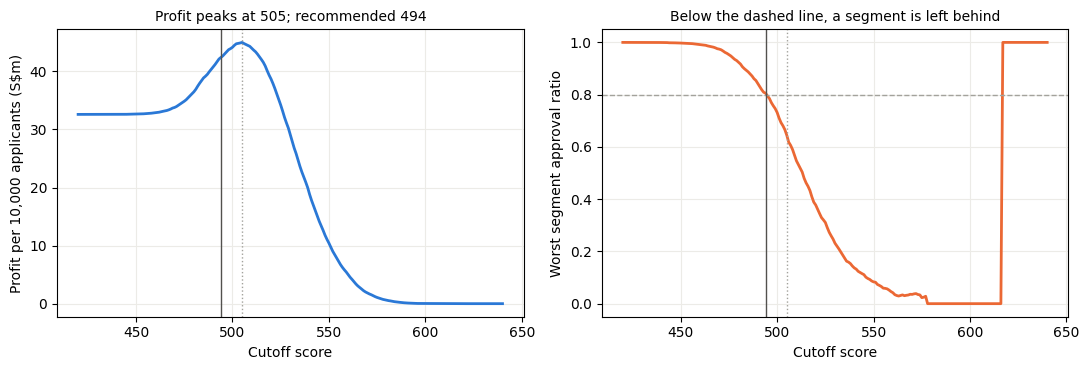

In [14]:
# Charts for the slides: profit by cutoff, and the worst segment ratio, with the recommended and most profitable cutoffs marked
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(grid["Cutoff"], grid["Profit_m"], color="#2a78d6", lw=2)
ax1.set_xlabel("Cutoff score"); ax1.set_ylabel("Profit per 10,000 applicants (S$m)")
ax2.plot(grid["Cutoff"], grid["Worst_segment_ratio"], color="#eb6834", lw=2)
ax2.axhline(MIN_APPROVAL_RATIO, color="#a3a29c", ls="--", lw=1)
ax2.set_xlabel("Cutoff score"); ax2.set_ylabel("Worst segment approval ratio")
for ax in (ax1, ax2):
    ax.axvline(CUTOFF, color="#52514e", lw=1); ax.axvline(PEAK_CUTOFF, color="#a3a29c", lw=1, ls=":")
    ax.grid(True, color="#ecebe7")
ax1.set_title(f"Profit peaks at {PEAK_CUTOFF}; recommended {CUTOFF}", fontsize=10)
ax2.set_title("Below the dashed line, a segment is left behind", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "profit_and_segments_by_cutoff.png", dpi=200); plt.show()

**How to read it.**
- **Recommendation: a cutoff of 494** (odds about 5.1:1, a PD of 16.4% in the score group at the cutoff). It approves 89.5% of applicants and 91.1% of good payers, and rejects 25.8% of Bads. The score groups expect 684 defaults per 10,000 applicants among those approved, against 683 that actually happened. That close match is expected on training data, since the PDs were read from these same applicants; section G checks it on unseen ones.
- **Why not higher?** At 495 the worst-treated group falls to 0.795 of the best group's approval rate, below the rule. At the most profitable cutoff, 505, the worst group falls to 0.645.
- **This has a cost.** Profit is S$42.41m against S$44.99m at 505, S$2.59m lower per 10,000 applicants.
- **Why a lower-scoring loan can lose money.** Each loan earns about S$11,950 of net interest over five years, and a default costs S$94,500, as much as the interest from 7.9 performing loans. So a loan breaks even at a PD of about 12.6%, which is a score of about 505. Applicants between 494 and 504 lose about S$2,020 per loan at a flat 2.00%, and earn about S$5,070 at the lowest band's 2.33% (section F).
- **The slide method overstates losses.** Using the PD at the cutoff for every approved loan, as on FA11.4 s11, profit would peak at 523. That treats every approved borrower as being as risky as the worst one.
- **Borderline cases.** Scores from 489 to 498 are 8.1% of applicants. They go to manual review (FA7.1 s11), which gives good payers just below the line a second look by a person.

**What a stricter cutoff would do, and who it would turn away.** The table compares the recommended cutoff with the most profitable one and with a stricter one, and shows which applicants the stricter cutoffs turn away.

In [15]:
age_train = segment_groups(train["SK_ID_CURR"], crossings=False)["Age"]
no_file_train = ~train["SK_ID_CURR"].isin(bureau_ids).to_numpy()
options = []
for label, c in [("Recommended", CUTOFF), ("Most profitable", PEAK_CUTOFF), ("Stricter", PEAK_CUTOFF + 10)]:
    row = grid[grid["Cutoff"] == c].iloc[0]
    ok = train_score >= c
    turned_away = (train_score >= CUTOFF) & ~ok
    options.append({"Option": label, "Cutoff": c, "Profit_m": row["Profit_m"], "Approval": row["Approval_rate"], "Specificity": row["Specificity_bads_rejected"],
                    "Worst_segment_ratio": row["Worst_segment_ratio"], "Goods_approved_21_29": ok[(y == 0) & (age_train == "21-29")].mean(),
                    "Goods_approved_50_55": ok[(y == 0) & (age_train == "50-55")].mean(),
                    "Good_payers_turned_away_per_10k": APPLICANTS * ((y == 0) & turned_away).sum() / len(y),
                    "Defaulters_avoided_per_10k": APPLICANTS * ((y == 1) & turned_away).sum() / len(y),
                    "Turned_away_aged_21_29": (age_train[turned_away] == "21-29").mean() if turned_away.any() else np.nan,
                    "Turned_away_no_file": no_file_train[turned_away].mean() if turned_away.any() else np.nan})
options = pd.DataFrame(options).set_index("Option")
display(options.round(3))
options.to_csv(OUT / "cutoff_options.csv")
print(f"Applicants aged 21-29: {(age_train == '21-29').mean():.1%} | under 40: {np.isin(age_train, ['21-29', '30-39']).mean():.1%} "
      f"| no bureau file: {no_file_train.mean():.1%} (21-29: {no_file_train[age_train == '21-29'].mean():.1%}, 50-55: {no_file_train[age_train == '50-55'].mean():.1%})")
print(f"Bad rate, 21-29: {y[age_train == '21-29'].mean():.1%} | 50-55: {y[age_train == '50-55'].mean():.1%}")
print(f"One default costs as much as the net interest from {LOSS_PER_DEFAULT / REVENUE_PER_LOAN:.1f} performing loans")

,Cutoff,Profit_m,Approval,Specificity,Worst_segment_ratio,Goods_approved_21_29,Goods_approved_50_55,Good_payers_turned_away_per_10k,Defaulters_avoided_per_10k,Turned_away_aged_21_29,Turned_away_no_file
Option,,,,,,,,,,,
Recommended,494,42.407,0.895,0.258,0.806,0.845,0.952,0.000,0.000,NaN,NaN
Most profitable,505,44.993,0.767,0.463,0.645,0.681,0.854,1091.416,188.918,0.309,0.169
Stricter,515,42.051,0.602,0.656,0.462,0.492,0.700,2565.607,366.769,0.285,0.180


Applicants aged 21-29: 23.4% | under 40: 60.6% | no bureau file: 14.0% (21-29: 19.6%, 50-55: 11.7%)
Bad rate, 21-29: 11.3% | 50-55: 6.4%
One default costs as much as the net interest from 7.9 performing loans


**Are the assumptions driving the answer?** Every business input is an assumption, so we vary the two most uncertain: loss given default and the spread after costs. Each cell shows the most profitable cutoff that still meets the segment rule, and its profit.

In [16]:
sens = {}
for lgd in (0.10, 0.20, 0.30, 0.40):
    for spread in (0.0040, 0.0055, 0.0070):
        g = cutoff_table(train_score, y, pd_train, train_tables, loss=LOAN_AMOUNT * lgd, revenue=LOAN_AMOUNT * AVG_BALANCE_SHARE * spread * HOLDING_YEARS)
        ok_rows = g[g["Worst_segment_ratio"] >= MIN_APPROVAL_RATIO]
        best = ok_rows.loc[ok_rows["Profit_m"].idxmax()]
        sens.setdefault(f"LGD {lgd:.0%}", {})[f"Spread {spread:.2%}"] = f"{int(best['Cutoff'])} (S${best['Profit_m']:.0f}m)"
display(pd.DataFrame(sens).T)
at_cut = grid[grid["Cutoff"] == CUTOFF].iloc[0]
print(f"At the recommended cutoff, profit turns negative if LGD exceeds about "
      f"{REVENUE_PER_LOAN * at_cut['Approved'] / (at_cut['Expected_defaults'] * LOAN_AMOUNT):.0%}")

,Spread 0.40%,Spread 0.55%,Spread 0.70%
LGD 10%,493 (S$46m),485 (S$76m),420 (S$109m)
LGD 20%,494 (S$13m),494 (S$42m),494 (S$72m)
LGD 30%,617 (S$0m),494 (S$10m),494 (S$39m)
LGD 40%,617 (S$0m),617 (S$0m),494 (S$7m)


At the recommended cutoff, profit turns negative if LGD exceeds about 33%


**How to read it.** At 20% LGD the recommended cutoff is 494 at every spread: the segment rule, not profit, sets the cutoff, so inclusion is the binding choice. Profit ranges from S$13m at a thin spread to S$72m at a wide one. At low LGD (10%) the bank could go further and approve more. At 30-40% LGD with a thin spread, no cutoff that meets the segment rule makes money (617 means approving almost no one), so the rule could not be kept at a flat rate. At the assumed 0.55% spread, the recommended cutoff breaks even at about 33% LGD; above that, inclusion at a flat rate would not pay.

## F. Interest rate determination
Interest rates must cover default risk and operating costs (FA7.1 s4), and should match the average risk of default for the portfolio (FA7.1 s8). So the rate is built from its parts:

$$\text{Rate} = \text{funding cost} + \text{operating cost} + \text{expected loss per year} + \text{target margin}$$

$$\text{Expected loss per year} = \frac{\text{expected default rate} \times LGD}{\text{average balance share} \times \text{holding period}}$$

The **portfolio rate** is one rate for everyone approved. FA7.2 s10 adds that terms can be adjusted by score: preferential rates for high scores and higher rates for low scores. So we also set a rate for each of four score bands. Rates are capped in practice by what competitors charge: banks' advertised packages were roughly 1.4%-2.2% in 2026, and the HDB concessionary loan is 2.60%.

In [17]:
def required_rate(default_rate, margin=TARGET_MARGIN):
    expected_loss = default_rate * LGD / (AVG_BALANCE_SHARE * HOLDING_YEARS)
    return FUNDING_COST + OPERATING_COST + expected_loss + margin

approved = train_score >= CUTOFF
portfolio_pd = pd_train[approved].mean()
PORTFOLIO_RATE = required_rate(portfolio_pd)
parts = pd.Series({"Funding cost": FUNDING_COST, "Operating cost": OPERATING_COST,
                   "Expected loss": portfolio_pd * LGD / (AVG_BALANCE_SHARE * HOLDING_YEARS), "Target margin": TARGET_MARGIN, "Portfolio rate": PORTFOLIO_RATE})
display((parts * 100).round(2).to_frame("% per year"))
print(f"Expected default rate among approved: {portfolio_pd:.2%} (actual {y[approved].mean():.2%}) | portfolio rate {PORTFOLIO_RATE:.2%}")

# Risk-based rates by score band (FA7.2 s10): four bands of approved applicants
edges = [CUTOFF] + list(np.quantile(train_score[approved], [0.25, 0.5, 0.75]).round()) + [int(highest) + 1]
bands = []
for low, high in zip(edges[:-1], edges[1:]):
    in_band = (train_score >= low) & (train_score < high)
    rate = required_rate(pd_train[in_band].mean())
    bands.append({"Score_band": f"{int(low)}-{int(high) - 1}", "Share_of_approved": in_band.sum() / approved.sum(), "Expected_PD": pd_train[in_band].mean(),
                  "Actual_bad_rate": y[in_band].mean(), "Risk_based_rate": rate, "Within_ceiling": rate <= RATE_CEILING})
pricing = pd.DataFrame(bands)
display(pricing.round(4))
pricing.to_csv(OUT / "pricing_bands.csv", index=False)
monthly = lambda r: LOAN_AMOUNT * (r / 12) / (1 - (1 + r / 12) ** -(25 * 12))
print(f"Monthly repayment on S${LOAN_AMOUNT:,.0f} over 25 years: at {PORTFOLIO_RATE:.2%} S${monthly(PORTFOLIO_RATE):,.0f}; "
      f"at the 4% MAS stress rate S${monthly(0.04):,.0f}, which needs S${monthly(0.04) / 0.30:,.0f} of monthly income under the 30% MSR")

# Profit by score band (FA11.4 s10-12), per 10,000 applicants; take-up is assumed not to change with the rate
def profit_m(rate, in_band, defaults):
    loans = APPLICANTS * in_band.mean()
    revenue = loans * LOAN_AMOUNT * AVG_BALANCE_SHARE * (rate - FUNDING_COST - OPERATING_COST) * HOLDING_YEARS
    return (revenue - APPLICANTS * defaults[in_band].sum() / len(defaults) * LOSS_PER_DEFAULT) / 1e6


def profit_by_band(scores, defaults):
    rows = []
    for name, low, high, rate in zip(["Higher risk", "Medium risk", "Lower risk", "Lowest risk"], edges[:-1], edges[1:], pricing["Risk_based_rate"]):
        in_band = (scores >= low) & (scores < high)
        rows.append({"Band": name, "Score_band": f"{int(low)}-{int(high) - 1}", "Loans_per_10k": APPLICANTS * in_band.mean(), "Default_rate": defaults[in_band].mean(), "Risk_based_rate": rate,
                     "Profit_m_flat_reference": profit_m(REFERENCE_RATE, in_band, defaults), "Profit_m_flat_portfolio": profit_m(PORTFOLIO_RATE, in_band, defaults),
                     "Profit_m_risk_based": profit_m(rate, in_band, defaults)})
    table = pd.DataFrame(rows).set_index("Band")
    table.loc["All approved"] = [f"{CUTOFF}+", table["Loans_per_10k"].sum(), defaults[scores >= CUTOFF].mean(), np.nan,
                                 table["Profit_m_flat_reference"].sum(), table["Profit_m_flat_portfolio"].sum(), table["Profit_m_risk_based"].sum()]
    return table


band_profit = profit_by_band(train_score, pd_train)
print(f"Profit by score band on training, S$m per 10,000 applicants, at the flat {REFERENCE_RATE:.2%}, the flat portfolio {PORTFOLIO_RATE:.2%} and the risk-based rates:")
display(band_profit.round(4))
band_profit.to_csv(OUT / "profit_by_band_train.csv")
assert np.isclose(band_profit.loc["All approved", "Profit_m_flat_reference"], chosen["Profit_m"])

borderline = (train_score >= CUTOFF) & (train_score < PEAK_CUTOFF)
per_loan = lambda rate: profit_m(rate, borderline, pd_train) * 1e6 / (APPLICANTS * borderline.mean())
print(f"Scores {CUTOFF} to {PEAK_CUTOFF - 1}: {borderline.mean():.1%} of applicants, expected default rate {pd_train[borderline].mean():.1%} | "
      f"profit per loan S${per_loan(REFERENCE_RATE):,.0f} at {REFERENCE_RATE:.2%}, S${per_loan(pricing['Risk_based_rate'].iloc[0]):,.0f} at {pricing['Risk_based_rate'].iloc[0]:.2%}")


,% per year
Funding cost,1.20
Operating cost,0.25
Expected loss,0.33
Target margin,0.30
Portfolio rate,2.08


Expected default rate among approved: 7.64% (actual 7.63%) | portfolio rate 2.08%


,Score_band,Share_of_approved,Expected_PD,Actual_bad_rate,Risk_based_rate,Within_ceiling
0,494-510,0.2480,0.1325,0.1325,0.0233,True
1,511-522,0.2450,0.0901,0.0898,0.0214,True
2,523-536,0.2461,0.0578,0.0572,0.0200,True
3,537-623,0.2609,0.0277,0.0282,0.0187,True


Monthly repayment on S$472,500 over 25 years: at 2.08% S$2,022; at the 4% MAS stress rate S$2,494, which needs S$8,313 of monthly income under the 30% MSR
Profit by score band on training, S$m per 10,000 applicants, at the flat 2.00%, the flat portfolio 2.08% and the risk-based rates:


,Score_band,Loans_per_10k,Default_rate,Risk_based_rate,Profit_m_flat_reference,Profit_m_flat_portfolio,Profit_m_risk_based
Band,,,,,,,
Higher risk,494-510,2219.9826,0.1325,0.0233,-1.2560,2.7019,14.4754
Medium risk,511-522,2193.1073,0.0901,0.0214,7.5475,11.4576,14.3002
Lower risk,523-536,2202.7903,0.0578,0.0200,14.3066,18.2339,14.3633
Lowest risk,537-623,2335.1909,0.0277,0.0187,21.8087,25.9720,15.2266
All approved,494+,8951.0711,0.0764,NaN,42.4068,58.3655,58.3655


Scores 494 to 504: 12.8% of applicants, expected default rate 14.8% | profit per loan S$-2,020 at 2.00%, S$5,066 at 2.33%


**How to read it.**
- **Portfolio rate: about 2.08%.** It is made up of funding 1.20%, operating cost 0.25%, expected loss 0.33% and margin 0.30%. The score groups expect 7.64% of approved applicants to default and 7.63% actually did. The rate sits near the top of advertised bank packages and below the 2.60% HDB concessionary rate.
- **Risk-based rates: 1.87% to 2.33%.** Each quarter of approved applicants has its own rate. The lowest band (494-510) expects 13.3% to default (actual 13.3%) and pays 2.33%; the highest (537 and above) expects 2.8% (actual 2.8%) and pays 1.87%. All four bands stay below the 2.60% ceiling, so inclusion does not depend on charging more than a borrower could pay elsewhere.
- **Profit by score band (FA11.4 s10-12), per 10,000 applicants.** At a flat 2.00%, the higher-risk band (494-510) loses S$1.26m while the safest band earns S$21.81m. At the risk-based rates every band earns about the same, S$14.30m to S$15.23m, about S$6,520 per loan, because each rate covers that band's own expected loss plus the same margin.
- **Risk-based pricing moves profit between bands; it does not create it.** Total profit is S$58.37m at the risk-based rates and also S$58.37m at a flat 2.08%, since both collect the same interest overall. Both are above the S$42.41m at 2.00% only because the average rate is higher. What risk-based pricing adds is fairness between borrowers: safer borrowers no longer subsidise riskier ones, and no band depends on another. These figures assume take-up does not change with the rate, which the data cannot test.
- **Affordability comes first.** At 2.08% the repayment is about S$2,020 a month. Under the 4% stress rate it is S$2,494, which needs about S$8,300 of gross monthly income under the 30% MSR for HDB and EC purchases (MAS, n.d.-b). These limits are checked before the scorecard.

**Everything is now fixed.** The cell below saves a copy of the scorecard points, the cutoff and the rates. The final cell compares them with the live values after the test set has been used and stops with an error if anything changed, which confirms that nothing was altered after the test set was used.

In [18]:
FROZEN = {"points": scorecard_table["points"].to_numpy().copy(), "cutoff": CUTOFF, "rates": pricing["Risk_based_rate"].to_numpy().copy()}

def model_unchanged():
    return bool(np.array_equal(FROZEN["points"], scorecard_table["points"].to_numpy()) and FROZEN["cutoff"] == CUTOFF
                and np.array_equal(FROZEN["rates"], pricing["Risk_based_rate"].to_numpy()))
assert "test" not in globals() and "test_score" not in globals(), "A test object exists before section G"
print("No test applicant's data has been loaded. Scorecard points, cutoff and rates are saved for the check after testing.")

No test applicant's data has been loaded. Scorecard points, cutoff and rates are saved for the check after testing.


# Component 4 continued: Model performance on unseen applicants
## G. Evaluation on the test set
**In this notebook the test applicants' data is opened only here.** Nothing above reads it: the characteristics, bins, cutoff and rates are all set on training data. We answer the two questions of FA11.3 s4: how well does the model fit the training data, and how well does it predict unseen applicants?

AUC: training 0.6975 (Poor) | test 0.6923 (Poor) | gap +0.0052


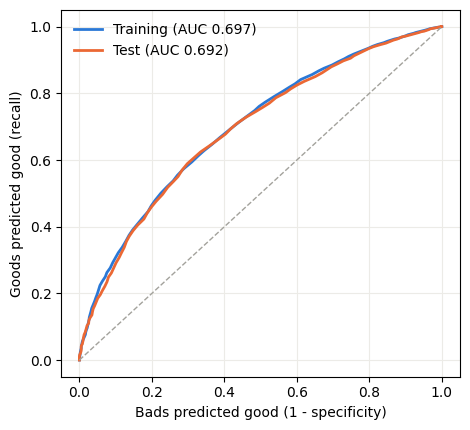

In [19]:
test = pd.read_csv(C3_DIR / "test.csv")
assert set(test["SK_ID_CURR"]) == set(test_ids)
y_test = test["TARGET"].to_numpy()
test_score = score_applicants(test)
pd_test = pd_from_score(test_score)

band = lambda a: "Not useful" if a < 0.6 else "Poor" if a < 0.7 else "Fair" if a < 0.8 else "Good" if a < 0.9 else "Excellent"   # FA11.3 s18
auc_train, auc_test = auc(y, train_score), auc(y_test, test_score)
print(f"AUC: training {auc_train:.4f} ({band(auc_train)}) | test {auc_test:.4f} ({band(auc_test)}) | gap {auc_train - auc_test:+.4f}")

# ROC curves (FA11.3 s16): y-axis = Goods predicted good, x-axis = Bads predicted good
fig, ax = plt.subplots(figsize=(4.8, 4.4))
for name, outcome, score, colour in (("Training", y, train_score, "#2a78d6"), ("Test", y_test, test_score, "#eb6834")):
    fpr, tpr, _ = metrics.roc_curve(1 - outcome, score)
    ax.plot(fpr, tpr, color=colour, lw=2, label=f"{name} (AUC {auc(outcome, score):.3f})")
ax.plot([0, 1], [0, 1], color="#a3a29c", ls="--", lw=1)
ax.set_xlabel("Bads predicted good (1 - specificity)"); ax.set_ylabel("Goods predicted good (recall)")
ax.legend(frameon=False); ax.grid(True, color="#ecebe7")
plt.tight_layout(); plt.savefig(OUT / "roc_train_test.png", dpi=200); plt.show()

**Confusion matrix and PCC measures at the recommended cutoff.** As in FA11.3 s7 and the Week 11 lab, *a good payer is the positive class*: approving a good borrower is a true positive, and approving a borrower who defaults is a false positive.

In [20]:
def show_performance(title, y_actual, scores, cutoff=CUTOFF):
    # Week 11 lab: labelled confusion matrix (Good payer = 0 is the positive class) and the classification report
    predicted = (scores < cutoff).astype(int)                 # 1 = predicted defaulter
    tp, fn, fp, tn = metrics.confusion_matrix(y_actual, predicted, labels=[0, 1]).ravel()
    print(f"*** {title} (cutoff {cutoff}) ***")
    print(pd.DataFrame([[f"{tp:,} (TP)", f"{fn:,} (FN)"], [f"{fp:,} (FP)", f"{tn:,} (TN)"]],
                       index=["Actual: Good payer", "Actual: Defaulter"], columns=["Predicted: Good payer", "Predicted: Defaulter"]).to_string())
    print(metrics.classification_report(y_actual, predicted, labels=[0, 1], target_names=["Good payer", "Defaulter"], digits=3))
    return {"Accuracy": (tp + tn) / len(y_actual), "Error rate": (fn + fp) / len(y_actual), "Recall (goods approved)": tp / (tp + fn),
            "Specificity (bads rejected)": tn / (tn + fp), "Precision (approved who repay)": tp / (tp + fp),
            "F1": 2 * tp / (2 * tp + fp + fn), "Approval rate": (tp + fp) / len(y_actual)}

pcc = pd.DataFrame({"Train": show_performance("Training data", y, train_score), "Test": show_performance("Test data", y_test, test_score)})
pcc["Gap (train - test)"] = pcc["Train"] - pcc["Test"]
pcc["Approve everyone (test)"] = [1 - y_test.mean(), y_test.mean(), 1.0, 0.0, 1 - y_test.mean(), 2 * (1 - y_test.mean()) / (2 - y_test.mean()), 1.0]
display(pcc.round(4))

*** Training data (cutoff 494) ***
                   Predicted: Good payer Predicted: Defaulter
Actual: Good payer           41,839 (TP)           4,109 (FN)
Actual: Defaulter             3,457 (FP)           1,199 (TN)
              precision    recall  f1-score   support

  Good payer      0.924     0.911     0.917     45948
   Defaulter      0.226     0.258     0.241      4656

    accuracy                          0.850     50604
   macro avg      0.575     0.584     0.579     50604
weighted avg      0.859     0.850     0.855     50604

*** Test data (cutoff 494) ***
                   Predicted: Good payer Predicted: Defaulter
Actual: Good payer           17,828 (TP)           1,864 (FN)
Actual: Defaulter             1,493 (FP)             503 (TN)
              precision    recall  f1-score   support

  Good payer      0.923     0.905     0.914     19692
   Defaulter      0.213     0.252     0.231      1996

    accuracy                          0.845     21688
   macro avg     

,Train,Test,Gap (train - test),Approve everyone (test)
Accuracy,0.8505,0.8452,0.0053,0.9080
Error rate,0.1495,0.1548,-0.0053,0.0920
Recall (goods approved),0.9106,0.9053,0.0052,1.0000
Specificity (bads rejected),0.2575,0.2520,0.0055,0.0000
Precision (approved who repay),0.9237,0.9227,0.0010,0.9080
F1,0.9171,0.9140,0.0031,0.9518
Approval rate,0.8951,0.8909,0.0042,1.0000


**Do the scores mean what they claim?** The Week 11 lab compares the number of defaults the scorecard expects, the sum of each approved applicant's PD, with the number that actually happened. Here each PD comes from the training score groups of section D, so this is a fair test: the test applicants played no part in that table. We do this for all approved test applicants and for each score band.

Approved test applicants: 19,321 | expected defaults 1477 | actual defaults 1,493


,Score_band,Applicants,Expected_defaults,Actual_defaults,Expected_bad_rate,Actual_bad_rate
0,429-479,672,175.538,177,0.261,0.263
1,480-499,2972,557.442,520,0.188,0.175
2,500-519,6987,759.924,782,0.109,0.112
3,520-539,6860,411.207,392,0.060,0.057
4,540-559,3237,89.760,109,0.028,0.034
5,560-623,960,13.998,16,0.015,0.017


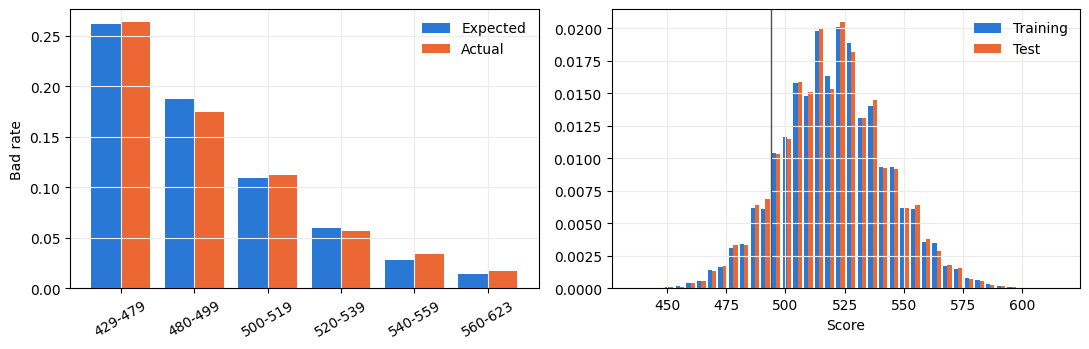

In [21]:
ok_test = test_score >= CUTOFF
print(f"Approved test applicants: {ok_test.sum():,} | expected defaults {pd_test[ok_test].sum():.0f} | actual defaults {y_test[ok_test].sum():,}")
band_edges = [int(lowest)] + list(range(480, 580, 20)) + [int(highest) + 1]
calib = []
for low, high in zip(band_edges[:-1], band_edges[1:]):
    m = (test_score >= low) & (test_score < high)
    if m.sum():
        calib.append({"Score_band": f"{low}-{high - 1}", "Applicants": int(m.sum()), "Expected_defaults": pd_test[m].sum(), "Actual_defaults": int(y_test[m].sum()),
                      "Expected_bad_rate": pd_test[m].mean(), "Actual_bad_rate": y_test[m].mean()})
calib = pd.DataFrame(calib)
display(calib.round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(calib))
ax1.bar(x - 0.2, calib["Expected_bad_rate"], 0.4, color="#2a78d6", label="Expected")
ax1.bar(x + 0.2, calib["Actual_bad_rate"], 0.4, color="#eb6834", label="Actual")
ax1.set_xticks(x); ax1.set_xticklabels(calib["Score_band"], rotation=30); ax1.set_ylabel("Bad rate"); ax1.legend(frameon=False)
ax2.hist([train_score, test_score], bins=40, color=["#2a78d6", "#eb6834"], label=["Training", "Test"], density=True)   # Week 11 lab
ax2.axvline(CUTOFF, color="#52514e", lw=1); ax2.set_xlabel("Score"); ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.grid(True, color="#ecebe7")
plt.tight_layout(); plt.savefig(OUT / "expected_vs_actual_and_scores.png", dpi=200); plt.show()

**Approvals and profit on the test set, and stability.** The Population Stability Index measures how far a score distribution has shifted (FA11.4 s13):

$$PSI = \sum (\%_{new} - \%_{dev}) \times \ln(\%_{new} / \%_{dev})$$

Training and test come from one random split, so a low PSI here is expected and says little about stability over time; the data has no application dates. The code is ready for the bank to monitor live applicants.

In [22]:
test_tables = []
min_group_test = MIN_GROUP_TRAIN * len(test) / len(train)
for values in segment_groups(test["SK_ID_CURR"]).values():
    labels, codes = np.unique(values.astype(str), return_inverse=True)
    usable = (np.bincount(codes) >= min_group_test) & ~np.array([("nan" in l) or ("XNA" in l) for l in labels])
    test_tables.append((codes, usable))
grid_test = cutoff_table(test_score, y_test, pd_test, test_tables)
grid_test.to_csv(OUT / "cutoff_grid_test.csv", index=False)
row_tr, row_te = grid[grid["Cutoff"] == CUTOFF].iloc[0], grid_test[grid_test["Cutoff"] == CUTOFF].iloc[0]
train_vs_test = pd.DataFrame({"Training": row_tr, "Test": row_te}).loc[["Approval_rate", "Recall_goods_approved", "Specificity_bads_rejected",
                        "Expected_defaults", "Actual_defaults", "Profit_m", "Profit_actual_defaults_m", "Worst_segment_ratio"]]
display(train_vs_test.astype(float).round(4))
print(f"Approving everyone instead (test): S${APPLICANTS * (REVENUE_PER_LOAN - y_test.mean() * LOSS_PER_DEFAULT) / 1e6:.1f}m per 10,000 applicants")

# The training bands and rates of section F, unchanged, with the defaults that actually happened in the test set
band_profit_test = profit_by_band(test_score, y_test.astype(float))
print("Profit by score band on the test set with actual defaults, S$m per 10,000 applicants:")
display(band_profit_test.round(4))
band_profit_test.to_csv(OUT / "profit_by_band_test.csv")

def psi(dev_scores, new_scores, edges):
    a = np.histogram(dev_scores, edges)[0] / len(dev_scores)
    b = np.histogram(new_scores, edges)[0] / len(new_scores)
    a, b = np.clip(a, 1e-6, None), np.clip(b, 1e-6, None)
    return float(np.sum((b - a) * np.log(b / a)))

psi_edges = np.unique(np.quantile(train_score, np.linspace(0, 1, 11)))
psi_edges[0], psi_edges[-1] = -np.inf, np.inf
print(f"Score PSI, training vs test: {psi(train_score, test_score, psi_edges):.4f}")

,Training,Test
Approval_rate,0.8951,0.8909
Recall_goods_approved,0.9106,0.9053
Specificity_bads_rejected,0.2575,0.2520
Expected_defaults,683.5610,680.8702
Actual_defaults,683.1476,688.3991
Profit_m,42.4068,42.1536
Profit_actual_defaults_m,42.4459,41.4421
Worst_segment_ratio,0.8058,0.8000


Approving everyone instead (test): S$32.6m per 10,000 applicants
Profit by score band on the test set with actual defaults, S$m per 10,000 applicants:


,Score_band,Loans_per_10k,Default_rate,Risk_based_rate,Profit_m_flat_reference,Profit_m_flat_portfolio,Profit_m_risk_based
Band,,,,,,,
Higher risk,494-510,2232.1099,0.1365,0.0233,-2.1182,1.8614,13.6991
Medium risk,511-522,2154.6477,0.0875,0.0214,7.9361,11.7775,14.5703
Lower risk,523-536,2189.6902,0.0554,0.0200,14.7165,18.6205,14.7729
Lowest risk,537-623,2332.1653,0.0316,0.0187,20.9077,25.0656,14.3341
All approved,494+,8908.6131,0.0773,NaN,41.4421,57.3250,57.3764


Score PSI, training vs test: 0.0006


**How to read it.**
- **Discrimination is modest but steady.** Test AUC is 0.692, against 0.697 on training, in the "Poor" band of FA11.3 s18. The 0.005 gap, and PCC gaps of 0.006 or less, show no overfitting.
- **At the cutoff of 494**, the bank approves 90.5% of good payers and rejects 25.2% of Bads. Of those approved, 92.3% repay. In this set, 1,864 good payers are turned away (FN) and 1,493 defaulters are approved (FP).
- **Accuracy alone would mislead.** Approving everyone scores 90.8% accuracy against our 84.5%, yet it catches no Bads and earns S$32.6m against S$41.4m per 10,000 applicants.
- **The PDs read from the score groups hold up on unseen applicants.** Among approved test applicants, 1,477 defaults were expected and 1,493 happened. By score band, expected and actual bad rates agree within 0.6 percentage points, except the 480-499 band, which is 1.3 points high (18.8% against 17.5%). The actual bad rate falls steadily at every step up the score bands, from 26.3% to 1.7%.
- **The cutoff holds up.** Test approval is 89.1% against 89.5% on training, specificity 25.2% against 25.8%, and profit S$41.4m against S$42.4m with actual defaults.
- **Profit by band holds up.** With the training bands and rates unchanged and the defaults that actually happened, the risk-based rates earn S$57.4m per 10,000 applicants on test, and every band is profitable (S$13.7m to S$14.8m). At a flat 2.00% the higher-risk band loses S$2.1m and the total is S$41.4m.
- **PSI of 0.0006** is expected from a random split. It is not evidence of stability over time, which the bank must monitor after launch (FA11.4 s13).

# Risks and limitations
## H. Approval and default rates by customer segment
Gender and age are not scorecard inputs (FA7.1 s14), but leaving them out does not guarantee fair outcomes, because other characteristics can be linked to them. So we measure outcomes for every group directly, on the test set and on training:
1. **Approval rate**, and the ratio to the best-treated group in the same family (the business rule of section E).
2. **Approval rate among actual good payers**: are creditworthy people treated alike?
3. **Expected against actual defaults**, as in the Week 11 lab: does the score read each group's risk correctly?

Groups smaller than 500 in training (214 in test) are left out of the ratios, because their rates are mostly noise.

In [23]:
def segment_table(ids, scores, pds, outcome, min_group):
    rows = []
    for family, values in segment_groups(ids).items():
        for g in sorted(pd.unique(values)):
            m = values == g
            if m.sum() < min_group or "nan" in g or "XNA" in g:
                continue
            ok = scores[m] >= CUTOFF
            rows.append({"Family": family, "Group": g, "Applicants": int(m.sum()), "Approval_rate": ok.mean(), "Goods_approved": ok[outcome[m] == 0].mean(),
                         "Actual_bad_rate": outcome[m].mean(), "Expected_bad_rate": pds[m].mean(),
                         "Bad_rate_approved": outcome[m][ok].mean() if ok.any() else np.nan})
    t = pd.DataFrame(rows)
    t["Impact_ratio"] = t["Approval_rate"] / t.groupby("Family")["Approval_rate"].transform("max")
    t["Goods_ratio"] = t["Goods_approved"] / t.groupby("Family")["Goods_approved"].transform("max")
    return t

seg_test = segment_table(test["SK_ID_CURR"], test_score, pd_test, y_test, min_group_test)
seg_train = segment_table(train["SK_ID_CURR"], train_score, pd_train, y, MIN_GROUP_TRAIN)
seg_test.to_csv(OUT / "segment_audit_test.csv", index=False)
summary_by_family = pd.DataFrame({"Lowest_ratio_train": seg_train.groupby("Family", sort=False)["Impact_ratio"].min(),
                                  "Lowest_ratio_test": seg_test.groupby("Family", sort=False)["Impact_ratio"].min(),
                                  "Group_lowest_on_test": seg_test.loc[seg_test.groupby("Family", sort=False)["Impact_ratio"].idxmin()].set_index("Family")["Group"],
                                  "Lowest_goods_ratio_test": seg_test.groupby("Family", sort=False)["Goods_ratio"].min()})
summary_by_family["Below_0.80_on_test"] = summary_by_family["Lowest_ratio_test"] < MIN_APPROVAL_RATIO
display(summary_by_family.round(3))
display(seg_test[seg_test["Family"].isin(["Age", "Bureau file", "Gender", "Education", "Age x Bureau file"])].round(3))

,Lowest_ratio_train,Lowest_ratio_test,Group_lowest_on_test,Lowest_goods_ratio_test,Below_0.80_on_test
Family,,,,,
Age,0.870,0.865,21-29,0.881,False
Gender,0.974,0.976,M,0.978,False
Family status,0.926,0.941,Single / not married,0.942,False
Children,0.960,0.979,0,0.978,False
Bureau file,0.928,0.924,Has a file,0.937,False
Product,0.940,0.942,Cash loans,0.950,False
Education,0.872,0.883,Lower secondary,0.912,False
Income type,0.898,0.889,Working,0.903,False
Housing,0.916,0.906,Rented apartment,0.909,False


,Family,Group,Applicants,Approval_rate,Goods_approved,Actual_bad_rate,Expected_bad_rate,Bad_rate_approved,Impact_ratio,Goods_ratio
0,Age,21-29,5072,0.813,0.833,0.115,0.115,0.092,0.865,0.881
1,Age,30-39,8108,0.895,0.911,0.098,0.091,0.082,0.953,0.964
2,Age,40-49,6110,0.930,0.939,0.074,0.082,0.065,0.990,0.993
3,Age,50-55,2398,0.940,0.946,0.072,0.079,0.066,1.000,1.000
4,Gender,F,12959,0.899,0.913,0.084,0.090,0.070,1.000,1.000
5,Gender,M,8729,0.878,0.893,0.104,0.097,0.089,0.976,0.978
15,Bureau file,Has a file,18617,0.881,0.897,0.087,0.093,0.070,0.924,0.937
16,Bureau file,No file,3071,0.953,0.957,0.120,0.089,0.116,1.000,1.000
19,Education,Higher education,5682,0.937,0.945,0.059,0.073,0.051,1.000,1.000
20,Education,Incomplete higher,1000,0.874,0.888,0.096,0.097,0.081,0.932,0.940


**How to read it.**
- **All ten families clear the rule on unseen applicants.** The lowest is age, at 0.865: 81.3% of 21-29 year olds are approved, against 94.0% of 50-55 year olds, and 83.3% of their good payers against 94.6%. The scorecard reads their risk exactly (11.5% expected, 11.5% actual). The remaining gap reflects a real difference in risk: 11.5% against 7.2%.
- **No-file applicants are served, but their risk is read low.** They are approved at 95.3% against 88.1% of those with a file. The scorecard expects 8.9% of them to default and 12.0% did. This is the effect of balanced class weights found in round 6: the no-file model treats its own group as average risk. Their approvals are not at risk, but their rates are set too low, so the bank should price or review no-file loans with this in mind.
- **All seven crossings clear it, but two have no margin.** 21-29 year olds with secondary education and 21-29 year olds with a bureau file are both at 0.800 on test (0.810 and 0.806 on training). A handful of applicants would change that, so we treat them as on the line rather than safely above it. The first group defaults at 13.9%, so much of the gap is real risk. Both should be the first groups monitored after launch, and their borderline cases go to manual review.
- **Fairness on approval is not the same as equal risk.** Leaving education out means some groups are approved despite higher risk. Lower-secondary applicants are the clearest case: the scorecard expects 11.5% to default and 17.7% did, in a small group of 220. Management should accept this knowingly or review these cases by hand.
- **Gender.** Men are scored slightly below their actual risk (9.7% expected, 10.4% actual) and women slightly above it (9.0% against 8.4%). This cannot be corrected without using gender, so it is reported for management to judge.
- **Limit of this audit.** The data has no race or religion field, so those groups cannot be measured.

# Component 7: Scorecard walkthrough
## I. Scoring three example applicants
These applicants are **made up for illustration**; they are not rows from the data. Each goes through the steps a loan officer's system would follow:
1. Check the regulatory limits (LTV, MSR, TDSR). These come first and are not part of the score.
2. Pick the scorecard for the applicant's segment (with or without a bureau file), look up each characteristic's points, as in the Week 11 lab's Ex Q1, and add them up. The tables show the full trail for each line: value, bin, WOE, coefficient and points (FA11.1 s8-9).
3. Read the odds and PD from the score, compare it with the cutoff, and set the rate from the score band.
   The four examples cover every outcome: approved, manual review on either side of the cutoff, and declined.
4. Give reasons: the characteristics where the applicant lost the most points against the best attribute, which supports the transparency a scorecard is chosen for (FA7.2 s3).

In [24]:
examples = pd.DataFrame({
    "A: established": {"EXT_SOURCE_1": 0.70, "BUR_DEBT_RATIO": 0.15, "BUR_MEAN_DAYS_CREDIT": -1500, "BUR_CARD_UTIL": 0.05, "BUR_ACTIVE_SHARE": 0.25,
                       "BUR_NEWEST_DAYS": -800, "BUR_CNT_LAST_24M": 0, "BUR_ANY_ADVERSE": 0, "OCCUPATION_TYPE": "Core staff", "DAYS_LAST_PHONE_CHANGE": -1600,
                       "ORGANIZATION_TYPE": "School", "NAME_INCOME_TYPE": "State servant", "FLAG_DOCUMENT_3": 0, "FLAG_OWN_CAR": "Y", "OWN_CAR_AGE": 4,
                       "YEARS_EMPLOYED": 9.0, "DAYS_ID_PUBLISH": -3000},
    "B: young buyer": {"EXT_SOURCE_1": 0.35, "BUR_DEBT_RATIO": 0.40, "BUR_MEAN_DAYS_CREDIT": -600, "BUR_CARD_UTIL": 0.60, "BUR_ACTIVE_SHARE": 0.50,
                       "BUR_NEWEST_DAYS": -250, "BUR_CNT_LAST_24M": 2, "BUR_ANY_ADVERSE": 0, "OCCUPATION_TYPE": "Sales staff", "DAYS_LAST_PHONE_CHANGE": -700,
                       "ORGANIZATION_TYPE": "Self-employed", "NAME_INCOME_TYPE": "Working", "FLAG_DOCUMENT_3": 1, "FLAG_OWN_CAR": "N", "OWN_CAR_AGE": np.nan,
                       "YEARS_EMPLOYED": 2.0, "DAYS_ID_PUBLISH": -1500},
    "C: no bureau file": {"EXT_SOURCE_1": np.nan, "BUR_DEBT_RATIO": np.nan, "BUR_MEAN_DAYS_CREDIT": np.nan, "BUR_CARD_UTIL": np.nan, "BUR_ACTIVE_SHARE": np.nan,
                          "BUR_NEWEST_DAYS": np.nan, "BUR_CNT_LAST_24M": np.nan, "BUR_ANY_ADVERSE": np.nan, "OCCUPATION_TYPE": "Laborers",
                          "DAYS_LAST_PHONE_CHANGE": -200, "ORGANIZATION_TYPE": "Construction", "NAME_INCOME_TYPE": "Working", "FLAG_DOCUMENT_3": 1,
                          "FLAG_OWN_CAR": "N", "OWN_CAR_AGE": np.nan, "YEARS_EMPLOYED": 4.0, "DAYS_ID_PUBLISH": -2500},
    "D: recent arrears": {"EXT_SOURCE_1": 0.25, "BUR_DEBT_RATIO": 0.85, "BUR_MEAN_DAYS_CREDIT": -500, "BUR_CARD_UTIL": 0.85, "BUR_ACTIVE_SHARE": 0.75,
                          "BUR_NEWEST_DAYS": -100, "BUR_CNT_LAST_24M": 3, "BUR_ANY_ADVERSE": 1, "OCCUPATION_TYPE": "Laborers", "DAYS_LAST_PHONE_CHANGE": -700,
                          "ORGANIZATION_TYPE": "Construction", "NAME_INCOME_TYPE": "Working", "FLAG_DOCUMENT_3": 1, "FLAG_OWN_CAR": "N", "OWN_CAR_AGE": np.nan,
                          "YEARS_EMPLOYED": 1.5, "DAYS_ID_PUBLISH": -1200},
}).T
missing_inputs = [v for v in FINAL_VARS if v not in examples.columns]
assert not missing_inputs, f"Add example values for {missing_inputs}"
examples = examples[FINAL_VARS]
for c in examples.columns:                                                   # numbers back to numeric type after building the table
    converted = pd.to_numeric(examples[c], errors="coerce")
    if converted.notna().sum() == examples[c].notna().sum():
        examples[c] = converted
EXAMPLE_HAS_FILE = {"A: established": True, "B: young buyer": True, "C: no bureau file": False, "D: recent arrears": True}
card_of = {n: ("Has a bureau file" if EXAMPLE_HAS_FILE[n] else "No bureau file") if SEGMENTED else "All applicants" for n in examples.index}
rows = []
for n in examples.index:
    vs = fitted[card_of[n]][1]
    pts = sc.scorecard_ply(examples.loc[[n], vs], cards[card_of[n]], only_total_score=False).iloc[0]    # Week 11 lab
    rows.append({**{v: pts.get(v + "_points", np.nan) for v in FINAL_VARS}, "score": pts["score"]})
points = pd.DataFrame(rows, index=examples.index)
sheet = pd.DataFrame(index=FINAL_VARS)
for n in examples.index:
    sheet[f"{n} value"] = examples.loc[n].map(lambda x: "Missing" if pd.isna(x) else x)
    sheet[f"{n} points"] = ["not scored" if pd.isna(points.loc[n, v]) else int(points.loc[n, v]) for v in FINAL_VARS]
display(sheet)
print("Scorecard used:", card_of)

best = {n: {v: cards[card_of[n]][v]["points"].max() for v in fitted[card_of[n]][1]} for n in examples.index}
def decision(score):
    if CUTOFF - REVIEW_BAND <= score < CUTOFF + REVIEW_BAND:
        return "Manual review"
    return "Approve" if score >= CUTOFF else "Decline"
def band_rate(score):
    for _, r in pricing.iterrows():
        low, high = map(int, r["Score_band"].split("-"))
        if low <= score <= high:
            return r["Risk_based_rate"]
    return np.nan
outcome = pd.DataFrame({"Score": points["score"]})
outcome["Odds_good_bad"] = [f"{float(odds_good(s)):.1f}:1" for s in outcome["Score"]]
outcome["PD"] = [float(pd_from_score(s)) for s in outcome["Score"]]
outcome["Decision"] = [decision(s) for s in outcome["Score"]]
outcome["Rate_if_approved"] = [band_rate(s) for s in outcome["Score"]]
outcome["Main_reasons_for_lost_points"] = [", ".join(f"{v} (-{int(best[n][v] - points.loc[n, v])})"
                                           for v in sorted(best[n], key=lambda v: points.loc[n, v] - best[n][v])[:3]) for n in examples.index]
display(outcome.round(4))
assert np.allclose(outcome["Score"].to_numpy(), points[FINAL_VARS].sum(axis=1).to_numpy())
outcome.to_csv(OUT / "walkthrough_examples.csv")

# The full trail for each applicant: value -> bin -> WOE -> coefficient -> points (FA11.1 s8-9)
trails = []
for n in examples.index:
    model_n, vs, bins_n = fitted[card_of[n]]
    woes = sc.woebin_ply(examples.loc[[n], vs], bins_n).iloc[0]                  # Week 11 lab
    for v, coefficient in zip(vs, model_n.coef_[0]):
        woe = woes[v + "_woe"]
        attribute = bins_n[v].iloc[(bins_n[v]["woe"] - woe).abs().argmin()]
        trails.append({"Applicant": n, "Characteristic": v, "Value": "Missing" if pd.isna(examples.loc[n, v]) else examples.loc[n, v],
                       "Bin": attribute["bin"].replace("%,%", ", ")[:44], "WOE": woe, "Coefficient": coefficient, "Points": int(points.loc[n, v])})
trails = pd.DataFrame(trails)
for n, trail in trails.groupby("Applicant", sort=False):
    print(f"*** {n}: {card_of[n]} scorecard | total {trail['Points'].sum()} points | {outcome.loc[n, 'Decision']} ***")
    display(trail.drop(columns="Applicant").set_index("Characteristic").round(4))
    assert trail["Points"].sum() == outcome.loc[n, "Score"]
trails.to_csv(OUT / "walkthrough_detail.csv", index=False)


,A: established value,A: established points,B: young buyer value,B: young buyer points,C: no bureau file value,C: no bureau file points,D: recent arrears value,D: recent arrears points
EXT_SOURCE_1,0.7,62,0.35,37,Missing,61,0.25,37
BUR_DEBT_RATIO,0.15,45,0.4,40,Missing,not scored,0.85,30
BUR_MEAN_DAYS_CREDIT,-1500.0,44,-600.0,37,Missing,not scored,-500.0,37
BUR_CARD_UTIL,0.05,47,0.6,40,Missing,not scored,0.85,32
BUR_NEWEST_DAYS,-800.0,45,-250.0,41,Missing,not scored,-100.0,36
OCCUPATION_TYPE,Core staff,45,Sales staff,36,Laborers,62,Laborers,36
DAYS_LAST_PHONE_CHANGE,-1600,45,-700,37,-200,62,-700,37
ORGANIZATION_TYPE,School,43,Self-employed,37,Construction,54,Construction,33
OWN_CAR_AGE,4.0,51,Missing,37,Missing,64,Missing,37
YEARS_EMPLOYED,9.0,42,2.0,36,4.0,67,1.5,36


Scorecard used: {'A: established': 'Has a bureau file', 'B: young buyer': 'Has a bureau file', 'C: no bureau file': 'No bureau file', 'D: recent arrears': 'Has a bureau file'}


,Score,Odds_good_bad,PD,Decision,Rate_if_approved,Main_reasons_for_lost_points
A: established,606.0,67.6:1,0.0146,Approve,0.0187,"ORGANIZATION_TYPE (-13), OCCUPATION_TYPE (-4), EXT_SOURCE_1 (-0)"
B: young buyer,497.0,5.1:1,0.1636,Manual review,0.0233,"EXT_SOURCE_1 (-25), ORGANIZATION_TYPE (-19), OWN_CAR_AGE (-14)"
C: no bureau file,493.0,5.1:1,0.1636,Manual review,NaN,"EXT_SOURCE_1 (-33), ORGANIZATION_TYPE (-17), FLAG_DOCUMENT_3 (-16)"
D: recent arrears,456.0,2.8:1,0.2612,Decline,NaN,"EXT_SOURCE_1 (-25), ORGANIZATION_TYPE (-23), BUR_DEBT_RATIO (-15)"


[INFO] converting into woe values ...
[INFO] converting into woe values ...
[INFO] converting into woe values ...
[INFO] converting into woe values ...
*** A: established: Has a bureau file scorecard | total 606 points | Approve ***


,Value,Bin,WOE,Coefficient,Points
Characteristic,,,,,
EXT_SOURCE_1,0.7,"[0.64,inf)",-0.9967,0.7865,62
BUR_DEBT_RATIO,0.15,"[-inf,0.25)",-0.3718,0.4808,45
BUR_MEAN_DAYS_CREDIT,-1500.0,"[-inf,-1300.0)",-0.3968,0.3896,44
BUR_CARD_UTIL,0.05,"[-inf,0.4)",-0.3991,0.6258,47
BUR_NEWEST_DAYS,-800.0,"[-inf,-600.0)",-0.3478,0.5163,45
OCCUPATION_TYPE,Core staff,"Managers, Core staff, Private service staff,",-0.3194,0.6012,45
DAYS_LAST_PHONE_CHANGE,-1600,"[-inf,-1500.0)",-0.3268,0.6177,45
ORGANIZATION_TYPE,School,"Trade: type 4, School, Services, Mobile, Ins",-0.1845,0.7122,43
OWN_CAR_AGE,4.0,"[-inf,8.0)",-0.4980,0.7743,51


*** B: young buyer: Has a bureau file scorecard | total 497 points | Manual review ***


,Value,Bin,WOE,Coefficient,Points
Characteristic,,,,,
EXT_SOURCE_1,0.35,"[0.2,0.4)",0.1375,0.7865,37
BUR_DEBT_RATIO,0.4,"[0.25,0.5), missing",-0.0435,0.4808,40
BUR_MEAN_DAYS_CREDIT,-600.0,"[-750.0,-400.0)",0.2603,0.3896,37
BUR_CARD_UTIL,0.6,"[0.4,0.75)",-0.0060,0.6258,40
BUR_NEWEST_DAYS,-250.0,"[-600.0,-200.0)",-0.1116,0.5163,41
OCCUPATION_TYPE,Sales staff,"Cleaning staff, HR staff, Secretaries, Waite",0.2068,0.6012,36
DAYS_LAST_PHONE_CHANGE,-700,"[-1100.0,inf)",0.1606,0.6177,37
ORGANIZATION_TYPE,Self-employed,"Industry: type 7, Trade: type 1, Trade: type",0.1301,0.7122,37
OWN_CAR_AGE,Missing,missing,0.1042,0.7743,37


*** C: no bureau file: No bureau file scorecard | total 493 points | Manual review ***


,Value,Bin,WOE,Coefficient,Points
Characteristic,,,,,
EXT_SOURCE_1,Missing,missing,0.1315,0.8507,61
OCCUPATION_TYPE,Laborers,"Cleaning staff, HR staff, Secretaries, Waite",0.2005,0.4921,62
DAYS_LAST_PHONE_CHANGE,-200,"[-1100.0,inf)",0.1255,0.7326,62
ORGANIZATION_TYPE,Construction,"Realtor, Legal Services, Agriculture, Constr",0.4910,0.7185,54
OWN_CAR_AGE,Missing,missing,0.0585,0.4808,64
YEARS_EMPLOYED,4.0,"[3.0,inf)",-0.1621,0.5781,67
NAME_INCOME_TYPE,Working,Working,0.1413,0.6999,62
FLAG_DOCUMENT_3,1,"[1.0,inf)",0.1110,0.9772,61


*** D: recent arrears: Has a bureau file scorecard | total 456 points | Decline ***


,Value,Bin,WOE,Coefficient,Points
Characteristic,,,,,
EXT_SOURCE_1,0.25,"[0.2,0.4)",0.1375,0.7865,37
BUR_DEBT_RATIO,0.85,"[0.75,inf)",0.6748,0.4808,30
BUR_MEAN_DAYS_CREDIT,-500.0,"[-750.0,-400.0)",0.2603,0.3896,37
BUR_CARD_UTIL,0.85,"[0.75,0.9500000000000001)",0.3974,0.6258,32
BUR_NEWEST_DAYS,-100.0,"[-200.0,-50.0)",0.2211,0.5163,36
OCCUPATION_TYPE,Laborers,"Cleaning staff, HR staff, Secretaries, Waite",0.2068,0.6012,36
DAYS_LAST_PHONE_CHANGE,-700,"[-1100.0,inf)",0.1606,0.6177,37
ORGANIZATION_TYPE,Construction,"Realtor, Legal Services, Agriculture, Constr",0.3453,0.7122,33
OWN_CAR_AGE,Missing,missing,0.1042,0.7743,37


**How to read it.**
- **A: established (606 points).** Nine years in the job and a 4-year-old car. The score is in the top score group, with odds of about 68:1 (a PD of 1.5%), so the applicant is approved in the top band at 1.87%. The only real points lost are on the employer group (-13) and the occupation (-4).
- **B: young buyer (497 points).** Two years in the job, no car, a modest external score and fairly high card use; age is not an input. The odds are about 5.1:1, a PD of 16.4%. The score is just above the cutoff of 494 but inside the manual review zone of 489-498, so a person checks the application before approval at the lowest band's 2.33%. This is the customer the inclusive cutoff exists for: a second look and a higher rate, instead of an automatic refusal. The largest lost points are the external score (-25), the employer group (-19) and having no car (-14). Short tenure costs only a few points, because tenure is a single split.
- **C: no bureau file (493 points, scored on the no-file scorecard).** The odds are about 5.1:1, a PD of 16.4%. The score is just below the cutoff but inside the manual review zone, so the application is reviewed by a person rather than declined outright. Having no bureau file is **not** the reason, since the no-file scorecard does not score bureau characteristics at all. The low score comes from the missing external score (-33), the employer group (-17) and the document flag (-16).

- **D: recent arrears (456 points).** A bureau file with a past overdue payment, debt at 85% of credit, high card use and a weak external score. The odds are about 2.8:1, a PD of 26.1%. The score is 33 points below the manual review zone, so the application is declined. The largest lost points are the external score (-25), the employer group (-23) and the debt ratio (-15), which give the applicant specific reasons for the decision.

The tables under the summary show each applicant's full trail, from value to bin, WOE, coefficient and points.

To follow A by hand, take each characteristic's points from the "Has a bureau file" scorecard in section D, add them up and compare the total with 494: 62 + 45 + 44 + 47 + 45 + 45 + 45 + 43 + 51 + 42 + 44 + 44 + 49 = 606.

## J. Limitations, summary numbers and references
**Limitations to state in the presentation**

*Data*
- **The outcome is a proxy.** `TARGET` records payment difficulties on past consumer loans, not default on a mortgage.
- **Sample bias.** Only approved applicants have outcomes, so risk among the weakest applicants may be understated (FA9.1 s19).
- **No application dates.** We cannot test stability over time, so the bank should monitor PSI from launch (FA11.4 s13).
- **Who the segment leaves out.** The segment keeps earned-income applicants aged 21-55 with no property. Older applicants and pensioners are outside it by design (FA9.1 s19).
- **Local fit.** Some employer and occupation codes have no Singapore meaning. In Singapore a car's COE lasts 10 years (LTA, n.d.), so the older-car bins would rarely apply.

*Model*
- **Modest power, by choice.** The test AUC of 0.692 is in the "Poor" band (FA11.3 s18). Leaving out background and city characteristics cost 0.0135 of training AUC (section C2), and loan-size characteristics were also left out, in exchange for a fairer scorecard that can score real mortgage applicants.
- **Inclusion has a real cost.** Specificity is 26% on test, and the bank gives up about S$2.59m per 10,000 applicants against the most profitable cutoff.
- **The segment rule has a thin margin.** Two crossings of 21-29 year olds, those with a bureau file and those with secondary education, came in at 0.800 on test against 0.806 and 0.810 on training, so the rule must be monitored rather than assumed.
- **Balanced class weights make the score scale relative.** The required `class_weight='balanced'` ranks applicants as well as the plain model, but its scores no longer carry real odds, so PDs come from training score groups (section D). Those groups, and the hand merges in them, have to be redone whenever the scorecard is refitted.
- **No-file risk is read low.** Because each segment's balanced model treats its group as average risk, no-file applicants are expected to default at 8.9% on test and 12.0% did. Their rates should be reviewed.
- **The no-file scorecard rests on less data.** It is built on 7,093 training applicants and leans heavily on the external score (46 points between its best and worst bins). `OWN_CAR_AGE` is kept on it to stay within 8-15 characteristics although its IV in that segment is only 0.012.
- **Reliance on `EXT_SOURCE_1`.** It is the strongest characteristic, comes from outside the bank and is missing for about half of applicants.
- **Two characteristics have a weak business story.** The document flag and the phone-change date add signal, but would need a confirmed meaning for a mortgage application.
- **Job tenure and car ownership are partly linked to age and gender.** Tenure is a single split to limit this, and car ownership is more common among men; both should be reviewed.

*Business*
- **The cutoff depends on assumptions.** At a flat 2.00% rate the recommended cutoff stops being profitable if LGD is above about 33%, and at low LGD the most profitable cutoff moves down (section E). The team should confirm the inputs.
- **Some approved applicants earn less than they risk at a flat rate.** Scores between 494 and about 505 need the risk-based rates of section F to be profitable.
- **Behaviour is not modelled.** Higher rates can attract riskier borrowers, and safe borrowers can refinance elsewhere. The profit at the risk-based rates assumes that everyone approved still takes the loan, so it is an upper estimate.
- **Age and the LTV limit.** The 75% limit drops if the loan runs past age 65 (MAS, n.d.-a), so older applicants would need a shorter tenure, which the profit figures do not model.

In [25]:
summary = pd.Series({
    "Applicants: train / test": f"{len(y):,} / {len(y_test):,} (no overlap, bad rate {y.mean():.2%} / {y_test.mean():.2%})",
    "Characteristics: retained by Component 3 -> final": f"{len(retained)} -> {len(FINAL_VARS)}",
    "Scaling": f"{POINTS0} points at 1:19 odds of default, {PDO} points to double",
    "Possible score range": f"{lowest:.0f} to {highest:.0f}",
    "AUC: training / test": f"{auc_train:.3f} / {auc_test:.3f}",
    "Cutoff": f"{CUTOFF} (odds {float(odds_good(CUTOFF)):.1f}:1, PD {float(pd_from_score(CUTOFF)):.1%}); most profitable {PEAK_CUTOFF}",
    "Test approval rate": f"{pcc.loc['Approval rate', 'Test']:.1%}",
    "Test recall (goods approved)": f"{pcc.loc['Recall (goods approved)', 'Test']:.1%}",
    "Test specificity (bads rejected)": f"{pcc.loc['Specificity (bads rejected)', 'Test']:.1%}",
    "Test bad rate: all -> approved": f"{y_test.mean():.2%} -> {y_test[ok_test].mean():.2%}",
    "Test expected vs actual defaults among approved": f"{pd_test[ok_test].sum():.0f} vs {y_test[ok_test].sum():,}",
    "Portfolio interest rate": f"{PORTFOLIO_RATE:.2%}",
    "Risk-based rates": " / ".join(f"{r:.2%}" for r in pricing["Risk_based_rate"]) + " (lowest to highest score band)",
    "Test profit per 10,000 applicants": f"S${row_te['Profit_actual_defaults_m']:.1f}m with actual defaults",
    "Test profit at the risk-based rates": f"S${band_profit_test.loc['All approved', 'Profit_m_risk_based']:.1f}m with actual defaults",
    "Lowest segment ratio: training / test": f"{summary_by_family['Lowest_ratio_train'].min():.3f} / {summary_by_family['Lowest_ratio_test'].min():.3f}",
    "Segment tables below 0.80 on test": f"{int(summary_by_family['Below_0.80_on_test'].sum())} of {len(summary_by_family)}",
}, name="Value").to_frame()
display(summary)
assert model_unchanged(), "The model changed after the test set was opened"
print("Scorecard points, cutoff and rates are unchanged after the test set was used.")
summary.to_csv(OUT / "summary_numbers.csv")
print("Files written to", OUT, ":", sorted(p.name for p in OUT.iterdir()))

,Value
Applicants: train / test,"50,604 / 21,688 (no overlap, bad rate 9.20% / 9.20%)"
Characteristics: retained by Component 3 -> final,25 -> 13
Scaling,"600 points at 1:19 odds of default, 20 points to double"
Possible score range,429 to 623
AUC: training / test,0.697 / 0.692
Cutoff,"494 (odds 5.1:1, PD 16.4%); most profitable 505"
Test approval rate,89.1%
Test recall (goods approved),90.5%
Test specificity (bads rejected),25.2%
Test bad rate: all -> approved,9.20% -> 7.73%


Scorecard points, cutoff and rates are unchanged after the test set was used.
Files written to component4_outputs : ['cutoff_grid_test.csv', 'cutoff_grid_train.csv', 'cutoff_options.csv', 'expected_vs_actual_and_scores.png', 'final_scorecard.csv', 'pricing_bands.csv', 'profit_and_segments_by_cutoff.png', 'profit_by_band_test.csv', 'profit_by_band_train.csv', 'roc_train_test.png', 'segment_audit_test.csv', 'summary_numbers.csv', 'tuning_path.csv', 'walkthrough_detail.csv', 'walkthrough_examples.csv']


**References**
*Course material* (cited in the text as FA*module* s*slide*)
- IS453 Financial Analytics. (2026). *Module 7.1: Lending credit risk overview; 7.2: Credit scorecard concepts* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Module 9.1: Data preparation; 9.3: ML for credit analysis* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Module 10.3: Coarse classing; 10.4: Data normalisation* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Module 11.1: Credit scorecard construction; 11.2: Scorecard scaling; 11.3: Scorecard performance evaluation; 11.4: Scorecard model considerations; 11.5: Credit scoring for retail lending* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Week 9, Week 10 and Week 11 labs* [Lab notebooks], including `scorecardpy` 0.1.9.7 (https://github.com/shichenxie/scorecardpy). Singapore Management University.
- IS453 Financial Analytics. (2026). *IS453 Group Assignment - Data* and *Data Dict* [Data set]. Singapore Management University.

*Business context* (web pages accessed November 2026; check live figures before presenting)
- Monetary Authority of Singapore. (n.d.-a). *Loan tenure and loan-to-value limits*. https://www.mas.gov.sg/regulation/explainers/new-housing-loans/loan-tenure-and-loan-to-value-limits
- Monetary Authority of Singapore. (n.d.-b). *Mortgage Servicing Ratio and Total Debt Servicing Ratio rules*. https://www.mas.gov.sg/regulation/explainers/new-housing-loans/msr-and-tdsr-rules
- Monetary Authority of Singapore. (2026). *Financial stability review 2026*. https://www.mas.gov.sg/-/media/mas-media-library/publications/financial-stability-review/2026/financial-stability-review-2026.pdf (3-month SORA, used for the funding cost)
- Housing & Development Board. (2026a). *Public housing data for 2nd quarter 2026, Annex C*. https://www.hdb.gov.sg/-/media/hdb-pulse/news/2026/20260724-2nd-quarter-2026-public-housing-data-and-upcoming-flat-supply/Annex-C.pdf (resale prices)
- Housing & Development Board. (2026b). *CPF housing grants for HDB flat buyers*. MyNiceHome. https://www.mynicehome.gov.sg/get-started/hdb-grants-guide/
- Land Transport Authority. (n.d.). *Certificate of Entitlement (COE) renewal*. OneMotoring. https://onemotoring.lta.gov.sg/content/onemotoring/home/owning/coe-renewal.html
- PropKaki. (2026). *How much does a 4-room HDB cost?* https://propkaki.sg/market/questions/how-much-does-a-4-room-hdb-cost (island-wide 4-room median, secondary source)
- RedBrick. (2026). *Compare the best home loans in Singapore 2026*. https://www.redbrick.sg/blog/best-home-loan-singapore/ (bank package rates, secondary source)
- Homejourney. (2026). *Homejourney guide to home loan interest rates in Singapore 2026*. https://www.homejourney.sg/blog/bank-home-loan-rate-comparison-2026-homejourney-safe-guide (2.60% HDB concessionary rate, secondary source)

*Team assumptions (not sourced):* LGD of 20%, holding period of 5 years, average balance of 92% of the loan, operating cost of 0.25% and target margin of 0.30%.